<a href="https://colab.research.google.com/github/swatijaincts/GENAI-Course/blob/main/VLM_from_scratch_3hr_class.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Vision-Language Models (VLMs) from Scratch


## What you will learn
1. How an image becomes a **sequence of tokens**
2. **Attention** and the **transformer block**, written by hand
3. The **Vision Transformer (ViT)**, the "eye" of every VLM
4. **CLIP**: we train a mini-CLIP that matches images with captions
5. **LLaVA-style VLMs**: we train a mini-VLM that answers questions about images
6. Other designs: **Flamingo** (cross-attention) and **BLIP-2** (Q-Former)
7. **Real pretrained VLMs**: CLIP, BLIP, SmolVLM

## Schedule (3 hours)
| Time | Part | Topic |
|---|---|---|
 0 | Setup and the three VLM families |
 1 | Images as tensors |
 2 | Attention, transformer blocks, ViT from scratch |
 3 | Text side + our toy dataset |
 4 | **Mini-CLIP from scratch** (short break while it trains) |
 5 | Pretrained CLIP under the microscope |
 6 | **Mini-LLaVA from scratch** + Flamingo / Q-Former |
 7 | Pretrained generative VLMs: BLIP, SmolVLM |
 8 | Wrap-up and exercises |

## Shape notation
| Letter | Meaning |
|---|---|
| `B` | batch size (how many examples at once) |
| `C, H, W` | channels (3 colors), height, width |
| `P` | patch size in pixels |
| `N` | number of image tokens (patches) |
| `D` | length of each token vector ("hidden size") |
| `T` | number of text tokens |
| `V` | vocabulary size (number of different words) |

---
# Part 0: Setup (0:00 – 0:10)

In [ ]:
%pip install -q "transformers>=4.46" accelerate   # install the Hugging Face library for pretrained models (-q = quiet output)

In [ ]:
import math                                  # math functions, e.g. square root and log
import random                                # random numbers (used to draw random shapes)
import time                                  # measure how long things take
import textwrap                              # wrap long text so it fits in plot titles
from io import BytesIO                       # treat downloaded bytes like a file

import numpy as np                           # arrays of numbers
import requests                              # download files from the internet
import torch                                 # PyTorch: tensors and neural networks
import torch.nn as nn                        # neural-network layers (Linear, LayerNorm, ...)
import torch.nn.functional as F              # functions such as softmax and cross_entropy
import matplotlib.pyplot as plt              # plotting
from PIL import Image, ImageDraw             # open images, and draw shapes on images

torch.manual_seed(0)                         # fix PyTorch's random numbers so results are repeatable
random.seed(0)                               # fix Python's random numbers
np.random.seed(0)                            # fix numpy's random numbers

if torch.cuda.is_available():                # is there a GPU?
    device = "cuda"                          # yes: use the GPU
else:                                        # no GPU
    device = "cpu"                           # use the CPU (slower, but works)
print("We are running on:", device)          # show which one we use

We are running on: cpu


## 0.1 What is a Vision-Language Model?

A **VLM** takes **images and text** as input and either
* **scores** how well an image and a text match (search, zero-shot classification), or
* **writes text** about an image (captions, answers to questions, chat).

There are three main families:

```
(a) DUAL ENCODER  (CLIP, SigLIP)
    image ──► [ Image Encoder ] ──► image vector ──┐
                                                   ├──► cosine similarity (how well do they match?)
    text  ──► [ Text Encoder  ] ──► text vector  ──┘

(b) VISUAL TOKENS AS A PREFIX  (LLaVA, Qwen-VL, SmolVLM)
    image ──► [ Vision Encoder ] ──► [ Projector ] ──► visual tokens ──┐
                                                                       ├──► [ Language Model ] ──► answer text
    text  ──► [ Tokenizer + Embedding ] ──────────────► text tokens ───┘

(c) CROSS-ATTENTION  (Flamingo, BLIP-2)
    image ──► [ Vision Encoder ] ──► [ Resampler ] ──► visual tokens
                                                          │ (text looks at them)
    text  ──► [ LM block ] ─► [ Cross-Attention ] ─► [ LM block ] ─► [ Cross-Attention ] ─► next word
```

We will **code (a) and (b) from scratch**, write the building blocks of (c), and then run real pretrained models.

---
# Part 1: Images as tensors (0:10 – 0:20)

For a computer, an image is a grid of numbers: **height × width × 3 colors**, each from 0 to 255.

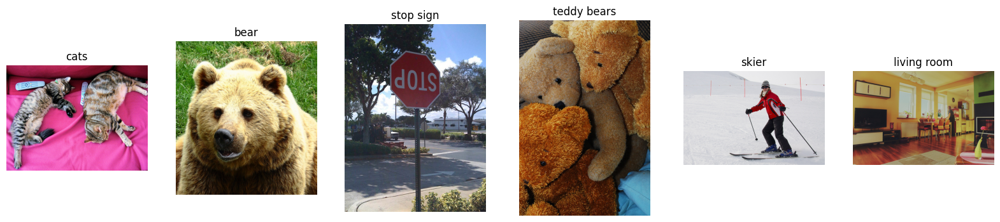

In [ ]:
image_urls = {                                                                   # dictionary: name -> web address of a photo (COCO dataset)
    "cats":        "http://images.cocodataset.org/val2017/000000039769.jpg",     # two cats on a couch
    "bear":        "http://images.cocodataset.org/val2017/000000000285.jpg",     # a brown bear
    "stop sign":   "http://images.cocodataset.org/val2017/000000000724.jpg",     # a stop sign (mounted upside-down!)
    "teddy bears": "http://images.cocodataset.org/val2017/000000000776.jpg",     # teddy bears
    "skier":       "http://images.cocodataset.org/val2017/000000000785.jpg",     # a woman skiing
    "living room": "http://images.cocodataset.org/val2017/000000000139.jpg",     # a living room
}


def load_image(url):                                       # function that downloads one image
    response = requests.get(url, timeout=30)               # download the file from the internet
    image = Image.open(BytesIO(response.content))          # open the downloaded bytes as an image
    image = image.convert("RGB")                           # make sure it has exactly 3 color channels
    return image                                           # give the image back


images = {}                                                # empty dictionary to store the images
for name in image_urls:                                    # go over every image name
    images[name] = load_image(image_urls[name])            # download the image and store it under its name

plt.figure(figsize=(20, 4))                                # create a wide, empty figure
for i, name in enumerate(images):                          # i = 0, 1, 2, ...   name = image name
    plt.subplot(1, len(images), i + 1)                     # select panel number i+1 (panels are in one row)
    plt.imshow(images[name])                               # draw the image in that panel
    plt.title(name)                                        # write the name above it
    plt.axis("off")                                        # hide the axis ticks
plt.show()                                                 # display the figure

shape (height, width, channels): (480, 640, 3)
data type: uint8
smallest value: 0
largest value: 255


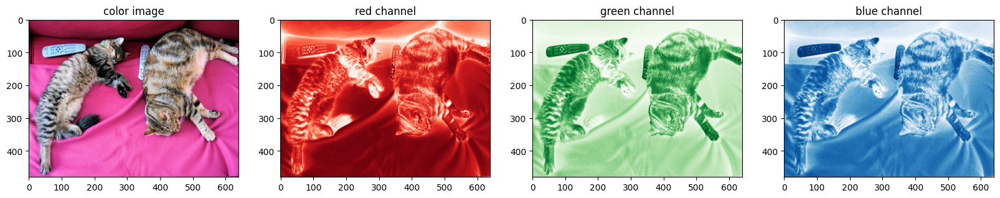

An 8x8 block of red values, as the computer sees it:
[[ 47  84 106 119 117 145 128 133]
 [ 58  65 107  75 126 126 139 139]
 [ 38  56  90  71  97 122 127 102]
 [ 40  40  81  50  63 122 122 132]
 [ 15  46  20  26  30  87 124 108]
 [ 15   5   6  18  43  64 106  55]
 [  2  12   0  26  35  65  84  22]
 [  4   2   1  19  23  40   6   5]]


In [ ]:
img = images["cats"]                                       # pick the cat photo
pixels = np.array(img)                                     # turn the picture into a numpy array of numbers
print("shape (height, width, channels):", pixels.shape)    # e.g. (480, 640, 3)
print("data type:", pixels.dtype)                          # uint8 = whole numbers from 0 to 255
print("smallest value:", pixels.min())                     # darkest value
print("largest value:", pixels.max())                      # brightest value

channel_names = ["red", "green", "blue"]                   # names of the 3 color channels
channel_colors = ["Reds", "Greens", "Blues"]               # matching color maps for plotting

plt.figure(figsize=(20, 4))                                # new wide figure
plt.subplot(1, 4, 1)                                       # panel 1
plt.imshow(pixels)                                         # show the full color image
plt.title("color image")                                   # title of panel 1
for c in range(3):                                         # c = 0 (red), 1 (green), 2 (blue)
    plt.subplot(1, 4, c + 2)                               # panels 2, 3, 4
    plt.imshow(pixels[:, :, c], cmap=channel_colors[c])    # show ONE channel: a 2-D grid of numbers
    plt.title(channel_names[c] + " channel")               # title
plt.show()                                                 # display

print("An 8x8 block of red values, as the computer sees it:")   # explain the next print
print(pixels[200:208, 300:308, 0])                         # rows 200-207, columns 300-307, channel 0 (red)

### Preprocessing: what every vision model does first
1. **Resize** to a fixed size (224 × 224)
2. **Scale** values from 0..255 to 0..1
3. **Channels first**: `(H, W, 3)` → `(3, H, W)` (this is PyTorch's convention)
4. **Normalize** each channel (subtract the mean, divide by the std), so values are around 0
5. Add a **batch dimension**: `(3, H, W)` → `(1, 3, H, W)`

one image: torch.Size([3, 224, 224])
a batch with one image: torch.Size([1, 3, 224, 224])


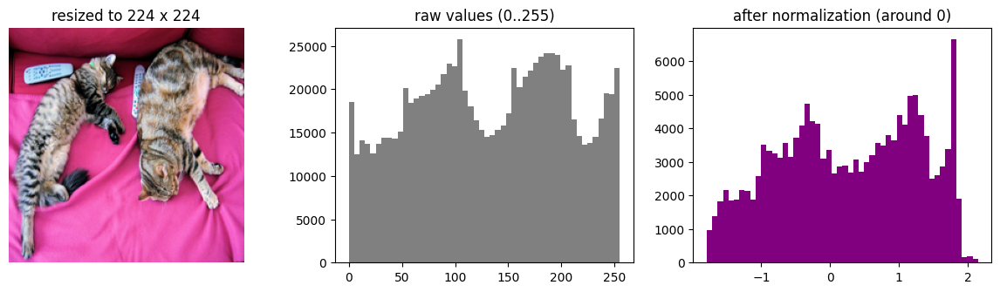

In [ ]:
mean = torch.tensor([0.4815, 0.4578, 0.4082]).reshape(3, 1, 1)   # average of each color channel in CLIP's training data, shape (3, 1, 1)
std = torch.tensor([0.2686, 0.2613, 0.2758]).reshape(3, 1, 1)    # spread of each color channel, shape (3, 1, 1)


def image_to_tensor(image, size=224):                      # PIL image -> normalized tensor (3, size, size)
    image = image.resize((size, size))                     # 1) resize to size x size pixels
    x = torch.tensor(np.array(image), dtype=torch.float32) # 2) numbers as a float tensor: (H, W, 3)
    x = x / 255.0                                          # 3) scale from 0..255 to 0..1
    x = x.permute(2, 0, 1)                                 # 4) move channels to the front: (3, H, W)
    x = (x - mean) / std                                   # 5) normalize every channel
    return x                                               # return the tensor


def tensor_to_image(x):                                    # the opposite, used only for plotting
    x = x.detach().cpu()                                   # make sure the tensor is on the CPU
    x = x * std + mean                                     # undo the normalization
    x = x.permute(1, 2, 0)                                 # channels last again: (H, W, 3)
    x = x.clamp(0, 1)                                      # keep values between 0 and 1
    return x.numpy()                                       # matplotlib wants numpy arrays


x = image_to_tensor(img)                                   # preprocess the cat photo
print("one image:", x.shape)                               # (3, 224, 224)
batch = x.unsqueeze(0)                                     # add a batch dimension in front
print("a batch with one image:", batch.shape)              # (1, 3, 224, 224)

plt.figure(figsize=(15, 3.5))                              # new figure
plt.subplot(1, 3, 1)                                       # panel 1
plt.imshow(tensor_to_image(x))                             # the resized image
plt.title("resized to 224 x 224")                          # title
plt.axis("off")                                            # no axis
plt.subplot(1, 3, 2)                                       # panel 2
plt.hist(pixels.flatten(), bins=50, color="gray")          # histogram of the raw pixel values
plt.title("raw values (0..255)")                           # title
plt.subplot(1, 3, 3)                                       # panel 3
plt.hist(x.flatten().numpy(), bins=50, color="purple")     # histogram after normalization
plt.title("after normalization (around 0)")                # title
plt.show()                                                 # display

---
# Part 2: Attention and the Vision Transformer (0:20 – 1:00)

Transformers read **sequences of vectors (tokens)**. Text is already a sequence of words. How do we turn an **image** into a sequence?

**ViT's idea: "An image is worth 16×16 words"**
1. Cut the image into small square **patches** (P × P pixels)
2. **Flatten** each patch into one long vector of `3·P·P` numbers
3. Map each vector to size `D` with a **linear layer**
4. Add a **[CLS] token** and **position embeddings**
5. Run several **transformer blocks**

## 2.1 Patchify: cut the image into patches

image batch: torch.Size([1, 3, 224, 224])
patches: torch.Size([1, 49, 3072])


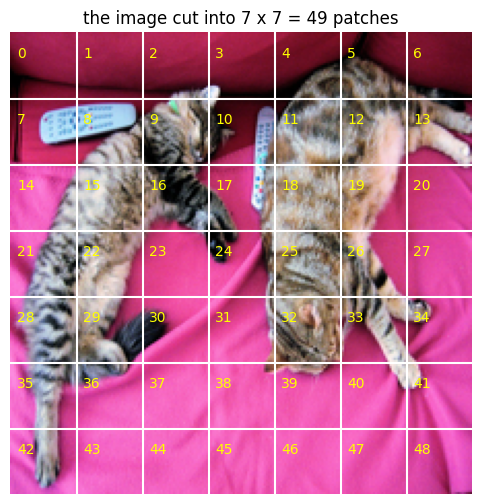

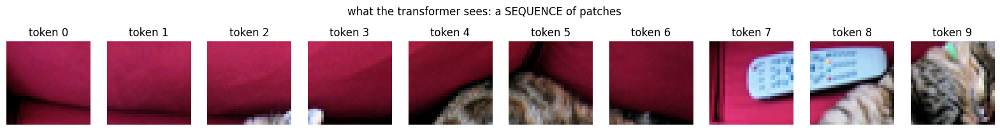

with patch size 16: torch.Size([1, 196, 768])


In [ ]:
def patchify(images, patch_size):                          # images: (B, 3, H, W)  ->  patches: (B, N, 3*P*P)
    B, C, H, W = images.shape                              # read the 4 sizes of the input
    patches = []                                           # empty list to collect the patches
    for row in range(0, H, patch_size):                    # top edge of each patch: 0, P, 2P, ...
        for col in range(0, W, patch_size):                # left edge of each patch: 0, P, 2P, ...
            patch = images[:, :, row:row + patch_size, col:col + patch_size]   # cut one square from every image: (B, 3, P, P)
            patch = patch.reshape(B, -1)                   # flatten the square into one long vector: (B, 3*P*P)
            patches.append(patch)                          # add it to the list
    patches = torch.stack(patches, dim=1)                  # stack the list along a new "sequence" axis: (B, N, 3*P*P)
    return patches                                         # return the sequence of patches


P = 32                                                     # big patches are easier to see (ViT-B/16 uses 16)
patches = patchify(batch, P)                               # cut the cat image into patches
print("image batch:", batch.shape)                         # (1, 3, 224, 224)
print("patches:", patches.shape)                           # (1, 49, 3072): 7*7 = 49 patches, each 3*32*32 = 3072 numbers
grid = 224 // P                                            # number of patches per side (7)

plt.figure(figsize=(6, 6))                                 # new figure
plt.imshow(tensor_to_image(batch[0]))                      # show the image
for k in range(1, grid):                                   # for every inner grid line
    plt.axhline(k * P, color="white")                      # draw a horizontal white line
    plt.axvline(k * P, color="white")                      # draw a vertical white line
number = 0                                                 # patch counter
for row in range(grid):                                    # for every row of patches
    for col in range(grid):                                # for every column of patches
        plt.text(col * P + 3, row * P + 12, str(number), color="yellow")   # write the patch number in its corner
        number = number + 1                                # next patch number
plt.title("the image cut into 7 x 7 = 49 patches")         # title
plt.axis("off")                                            # no axis
plt.show()                                                 # display

plt.figure(figsize=(20, 2.5))                              # wide figure for the sequence
for i in range(10):                                        # show the first 10 patches
    row = i // grid                                        # which row of the grid this patch is in
    col = i % grid                                         # which column
    patch = batch[0, :, row * P:(row + 1) * P, col * P:(col + 1) * P]   # cut that patch: (3, 32, 32)
    plt.subplot(1, 10, i + 1)                              # panel i+1
    plt.imshow(tensor_to_image(patch))                     # draw the patch
    plt.title("token " + str(i))                           # its position in the sequence
    plt.axis("off")                                        # no axis
plt.suptitle("what the transformer sees: a SEQUENCE of patches")   # overall title
plt.show()                                                 # display

patches16 = patchify(batch, 16)                            # now with the real ViT-B/16 patch size
print("with patch size 16:", patches16.shape)              # (1, 196, 768): 14*14 = 196 patches, each 3*16*16 = 768 numbers

## 2.2 Patch embedding, [CLS] token and position embeddings
* **Patch embedding:** one `nn.Linear` maps every flattened patch to a vector of size `D`. (Real code often uses `nn.Conv2d(kernel_size=P, stride=P)`, which computes exactly the same thing.)
* **[CLS] token:** an extra learnable vector at the start of the sequence. After the transformer, it holds a **summary of the whole image**.
* **Position embedding:** a learnable vector added to each token so the model knows **where** the patch came from. Without it, attention cannot tell positions apart (we prove this in 2.5).

In [ ]:
D = 768                                                    # size of every token vector (ViT-Base uses 768)
patch_embedding = nn.Linear(3 * 16 * 16, D)                # linear layer: 768 numbers in -> D numbers out
cls_token = nn.Parameter(torch.zeros(1, 1, D))             # one learnable [CLS] vector: (1, 1, D)
position_embedding = nn.Parameter(torch.randn(1, 197, D) * 0.02)   # one learnable vector per position: 1 CLS + 196 patches

tokens = patch_embedding(patches16)                        # embed every patch
print("1) patch tokens:", tokens.shape)                    # (1, 196, 768)
cls = cls_token.repeat(1, 1, 1)                            # copy the CLS token once per image in the batch (B=1 here)
tokens = torch.cat([cls, tokens], dim=1)                   # put [CLS] in front of the patches
print("2) with [CLS] in front:", tokens.shape)             # (1, 197, 768)
tokens = tokens + position_embedding                       # add the position information
print("3) after adding positions:", tokens.shape)          # (1, 197, 768): the shape does not change

1) patch tokens: torch.Size([1, 196, 768])
2) with [CLS] in front: torch.Size([1, 197, 768])
3) after adding positions: torch.Size([1, 197, 768])


## 2.3 Attention from scratch

Attention lets every token **collect information from the other tokens**. Each token makes three vectors:
* **Query** `q`: "what am I looking for?"
* **Key** `k`: "what do I contain?"
* **Value** `v`: "what do I give if someone picks me?"

$$\text{Attention}(Q,K,V) = \text{softmax}\left(\frac{QK^\top}{\sqrt{d}}\right)V$$

It is like a **soft dictionary lookup**: compare the query with every key, turn the scores into weights that sum to 1, and return the weighted average of the values.

weights: tensor([[0.0291, 0.9156, 0.0338, 0.0215]])
output: tensor([[20.4777]])


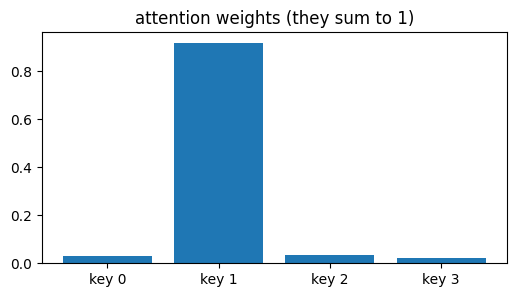

In [ ]:
def attention(q, k, v, mask=None):                         # q: (..., Nq, d)  k: (..., Nk, d)  v: (..., Nk, dv)
    d = q.shape[-1]                                        # length of each query/key vector
    scores = q @ k.transpose(-2, -1)                       # dot product of every query with every key: (..., Nq, Nk)
    scores = scores / math.sqrt(d)                         # scale down so the softmax is not too extreme
    if mask is not None:                                   # if a mask was given ...
        scores = scores.masked_fill(mask == 0, float("-inf"))   # ... forbid blocked positions (weight becomes 0)
    weights = torch.softmax(scores, dim=-1)                # turn scores into weights; every row sums to 1
    output = weights @ v                                   # weighted average of the values: (..., Nq, dv)
    return output, weights                                 # return both the result and the weights


# --- A tiny example: a "soft dictionary" with 4 entries ---
keys = torch.eye(4) * 3                                    # 4 keys, each pointing in a different direction: (4, 4)
values = torch.tensor([[10.0], [20.0], [30.0], [40.0]])    # the value stored under each key: (4, 1)
query = torch.tensor([[0.2, 2.5, 0.3, 0.0]])               # a query that looks most like key number 1: (1, 4)
output, weights = attention(query, keys, values)           # run attention
print("weights:", weights)                                 # most weight goes to key 1
print("output:", output)                                   # close to 20, the value of key 1

plt.figure(figsize=(6, 3))                                 # small figure
plt.bar(["key 0", "key 1", "key 2", "key 3"], weights[0].numpy())   # bar for each weight
plt.title("attention weights (they sum to 1)")             # title
plt.show()                                                 # display

queries: torch.Size([6, 8])
weights: torch.Size([6, 6])
output: torch.Size([6, 8])


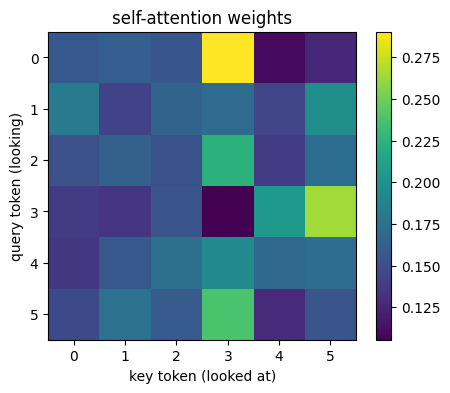

In [ ]:
# --- Self-attention: queries, keys and values all come from the SAME 6 tokens ---
tokens6 = torch.randn(6, 16)                               # 6 random tokens, each of length 16: (6, 16)
make_q = nn.Linear(16, 8)                                  # layer that turns a token into a query
make_k = nn.Linear(16, 8)                                  # layer that turns a token into a key
make_v = nn.Linear(16, 8)                                  # layer that turns a token into a value
q = make_q(tokens6)                                        # queries: (6, 8)
k = make_k(tokens6)                                        # keys: (6, 8)
v = make_v(tokens6)                                        # values: (6, 8)
output, weights = attention(q, k, v)                       # run attention
print("queries:", q.shape)                                 # (6, 8)
print("weights:", weights.shape)                           # (6, 6): every token looks at every token
print("output:", output.shape)                             # (6, 8): one new vector per token

plt.figure(figsize=(5, 4))                                 # figure
plt.imshow(weights.detach(), cmap="viridis")               # show the 6x6 weight matrix as colors
plt.xlabel("key token (looked at)")                        # x axis label
plt.ylabel("query token (looking)")                        # y axis label
plt.title("self-attention weights")                        # title
plt.colorbar()                                             # color scale
plt.show()                                                 # display

### Why divide by √d?
Dot products of long random vectors are **big numbers**. Softmax of big numbers is almost **one-hot**: one weight is 1 and all others are 0, so the model barely learns. Dividing by √d keeps the scores in a reasonable range.

spread of raw scores: 24.21393585205078
spread of scaled scores: 1.0701149702072144


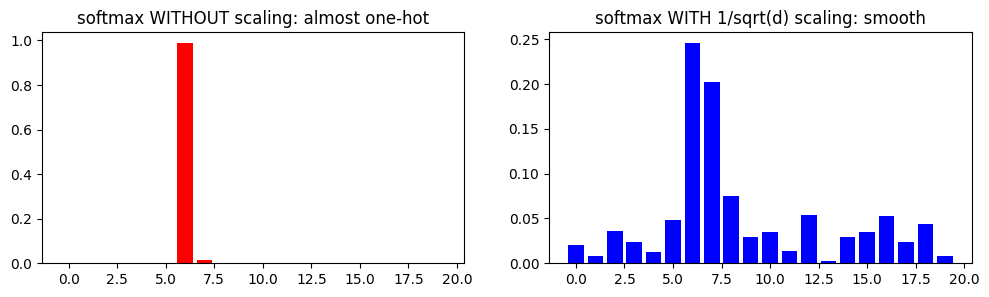

In [ ]:
d = 512                                                    # a typical vector length
q1 = torch.randn(1, d)                                     # one random query
k20 = torch.randn(20, d)                                   # 20 random keys
raw_scores = (q1 @ k20.T)[0]                               # 20 dot products WITHOUT scaling
scaled_scores = raw_scores / math.sqrt(d)                  # the same, WITH scaling
print("spread of raw scores:", raw_scores.std().item())    # about sqrt(512) = 22.6
print("spread of scaled scores:", scaled_scores.std().item())   # about 1

plt.figure(figsize=(12, 3))                                # wide figure
plt.subplot(1, 2, 1)                                       # left panel
plt.bar(range(20), torch.softmax(raw_scores, dim=0).numpy(), color="red")      # softmax without scaling
plt.title("softmax WITHOUT scaling: almost one-hot")       # title
plt.subplot(1, 2, 2)                                       # right panel
plt.bar(range(20), torch.softmax(scaled_scores, dim=0).numpy(), color="blue")  # softmax with scaling
plt.title("softmax WITH 1/sqrt(d) scaling: smooth")        # title
plt.show()                                                 # display

### The causal mask
* **Vision encoders** use no mask: every patch can see every patch.
* **Language models** use a **causal mask**: word *t* can only see words 1..t, so it cannot "cheat" by looking at the next word it has to predict.

tensor([[1., 0., 0., 0., 0., 0.],
        [1., 1., 0., 0., 0., 0.],
        [1., 1., 1., 0., 0., 0.],
        [1., 1., 1., 1., 0., 0.],
        [1., 1., 1., 1., 1., 0.],
        [1., 1., 1., 1., 1., 1.]])


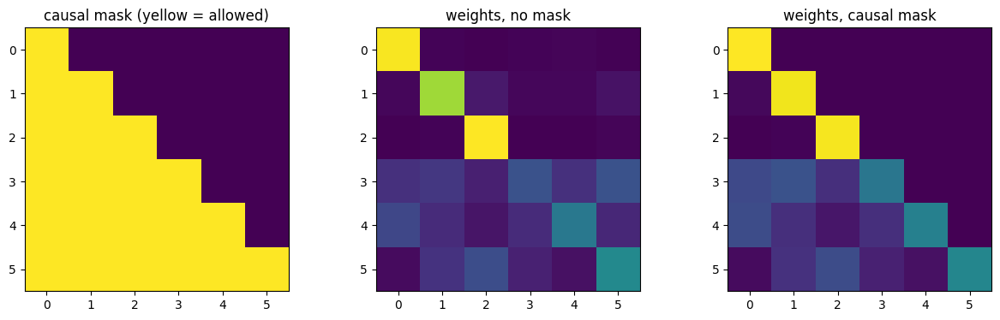

In [ ]:
T = 6                                                      # 6 tokens
causal_mask = torch.tril(torch.ones(T, T))                 # lower-triangle matrix of ones: 1 = allowed, 0 = blocked
print(causal_mask)                                         # print it
x6 = torch.randn(T, 8)                                     # 6 random tokens
_, weights_no_mask = attention(x6, x6, x6)                 # attention without a mask
_, weights_masked = attention(x6, x6, x6, causal_mask)     # attention with the causal mask

plt.figure(figsize=(15, 4))                                # wide figure
plt.subplot(1, 3, 1)                                       # panel 1
plt.imshow(causal_mask)                                    # show the mask
plt.title("causal mask (yellow = allowed)")                # title
plt.subplot(1, 3, 2)                                       # panel 2
plt.imshow(weights_no_mask)                                # weights without mask
plt.title("weights, no mask")                              # title
plt.subplot(1, 3, 3)                                       # panel 3
plt.imshow(weights_masked)                                 # weights with mask: upper triangle is 0
plt.title("weights, causal mask")                          # title
plt.show()                                                 # display

## 2.4 Multi-head attention
Instead of one attention, we run **several small attentions ("heads") side by side** and glue (concatenate) their outputs together. Each head can learn a different kind of relation (color, neighbors, same object, ...).

To keep it simple, each head is its own small module, and we loop over the heads.

The `context` argument also gives us **cross-attention**: queries come from `x`, keys and values come from `context`. We reuse this later for Flamingo and the Q-Former.

input: torch.Size([2, 10, 64])
output: torch.Size([2, 10, 64])
weights of all heads: torch.Size([2, 4, 10, 10])


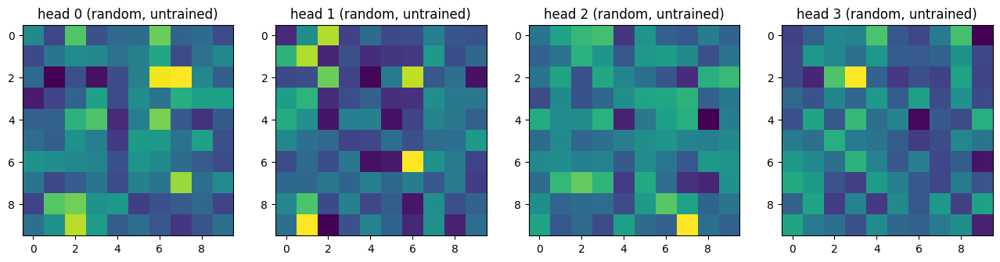

In [ ]:
class AttentionHead(nn.Module):                            # ONE attention head
    def __init__(self, dim, head_dim):                     # dim = token size, head_dim = size inside this head
        super().__init__()                                 # set up PyTorch's module machinery
        self.query = nn.Linear(dim, head_dim)              # layer that makes queries
        self.key = nn.Linear(dim, head_dim)                # layer that makes keys
        self.value = nn.Linear(dim, head_dim)              # layer that makes values
        self.weights = None                                # will remember the last attention weights (for plots)

    def forward(self, x, context, mask=None):              # x: (B, N, dim)   context: (B, M, dim)
        q = self.query(x)                                  # queries from x: (B, N, head_dim)
        k = self.key(context)                              # keys from the context: (B, M, head_dim)
        v = self.value(context)                            # values from the context: (B, M, head_dim)
        output, weights = attention(q, k, v, mask)         # run attention: output (B, N, head_dim)
        self.weights = weights.detach()                    # remember the weights (B, N, M) for plotting
        return output                                      # return the result


class MultiHeadAttention(nn.Module):                       # SEVERAL heads side by side
    def __init__(self, dim, num_heads):                    # dim must be divisible by num_heads
        super().__init__()                                 # set up PyTorch's module machinery
        head_dim = dim // num_heads                        # each head gets an equal share of the dimensions
        self.heads = nn.ModuleList()                       # a list that PyTorch knows contains layers
        for _ in range(num_heads):                         # create num_heads heads
            self.heads.append(AttentionHead(dim, head_dim))   # add one head to the list
        self.output_layer = nn.Linear(dim, dim)            # mixes the outputs of all heads

    def forward(self, x, context=None, mask=None):         # x: (B, N, dim)
        if context is None:                                # no context given ...
            context = x                                    # ... so x looks at itself (SELF-attention)
        head_outputs = []                                  # list for the output of every head
        for head in self.heads:                            # loop over the heads
            head_outputs.append(head(x, context, mask))    # each output: (B, N, head_dim)
        x = torch.cat(head_outputs, dim=-1)                # glue the heads together: (B, N, dim)
        x = self.output_layer(x)                           # mix them: (B, N, dim)
        return x                                           # return the result

    def attention_weights(self):                           # helper to read the weights of all heads
        all_weights = []                                   # empty list
        for head in self.heads:                            # loop over the heads
            all_weights.append(head.weights)               # each: (B, N, M)
        return torch.stack(all_weights, dim=1)             # stack them: (B, heads, N, M)


mha = MultiHeadAttention(dim=64, num_heads=4)              # 4 heads, token size 64 (16 per head)
x_tokens = torch.randn(2, 10, 64)                          # B=2 examples, N=10 tokens, D=64
y_tokens = mha(x_tokens)                                   # run multi-head self-attention
print("input:", x_tokens.shape)                            # (2, 10, 64)
print("output:", y_tokens.shape)                           # (2, 10, 64): same shape as the input
print("weights of all heads:", mha.attention_weights().shape)   # (2, 4, 10, 10)

plt.figure(figsize=(16, 3.5))                              # wide figure
for h in range(4):                                         # for every head
    plt.subplot(1, 4, h + 1)                               # panel h+1
    plt.imshow(mha.attention_weights()[0, h])              # attention map of head h for the first example
    plt.title("head " + str(h) + " (random, untrained)")   # title
plt.show()                                                 # display

## 2.5 Experiment: attention does not know about order
If we **shuffle** the input tokens, self-attention gives the **same outputs, shuffled the same way**. So without position embeddings, a ViT would see a "bag of patches" with no layout.

In [ ]:
mha_small = MultiHeadAttention(dim=32, num_heads=4)        # a small attention layer
xs = torch.randn(1, 6, 32)                                 # 6 tokens
order = torch.tensor([3, 0, 5, 1, 4, 2])                   # a shuffled order of the 6 positions

result_a = mha_small(xs)[:, order]                         # attend first, then shuffle the outputs
result_b = mha_small(xs[:, order])                         # shuffle the inputs first, then attend
print("WITHOUT positions, same result?", torch.allclose(result_a, result_b, atol=1e-5))   # True

positions = torch.randn(1, 6, 32)                          # position vectors belong to SLOTS (they do not move)
result_a = mha_small(xs + positions)[:, order]             # attend first (with positions), then shuffle
result_b = mha_small(xs[:, order] + positions)             # shuffle the tokens, keep positions in place, then attend
print("WITH positions,    same result?", torch.allclose(result_a, result_b, atol=1e-5))   # False: order now matters

WITHOUT positions, same result? True
WITH positions,    same result? False


## 2.6 The transformer block
A block = **attention** (tokens share information) + **MLP** (each token is processed on its own). Each part has a **LayerNorm** before it and a **residual connection** ("+ x") around it.

```
x ──► LayerNorm ──► Multi-Head Attention ──► (+) ──► LayerNorm ──► MLP ──► (+) ──► output
│                                             ▲  │                           ▲
└─────────────────────────────────────────────┘  └───────────────────────────┘
                  residual connection                residual connection
```

In [ ]:
class TransformerBlock(nn.Module):                         # one transformer block
    def __init__(self, dim, heads):                        # dim = token size, heads = number of heads
        super().__init__()                                 # set up PyTorch's module machinery
        self.norm1 = nn.LayerNorm(dim)                     # normalization before attention
        self.attention = MultiHeadAttention(dim, heads)    # the attention layer
        self.norm2 = nn.LayerNorm(dim)                     # normalization before the MLP
        self.mlp = nn.Sequential(                          # a small 2-layer network applied to every token
            nn.Linear(dim, 4 * dim),                       # make the token 4x wider
            nn.GELU(),                                     # non-linearity (a smooth version of ReLU)
            nn.Linear(4 * dim, dim),                       # back to the original width
        )

    def forward(self, x, mask=None):                       # x: (B, N, dim)
        x = x + self.attention(self.norm1(x), mask=mask)   # tokens talk to each other, then add the input back (residual)
        x = x + self.mlp(self.norm2(x))                    # every token is processed alone, then add the input back
        return x                                           # same shape as the input: (B, N, dim)


block = TransformerBlock(dim=768, heads=12)                # one block of the size used in ViT-Base
n_params = sum(p.numel() for p in block.parameters())      # count all numbers the block can learn
print("parameters in one ViT-Base block:", n_params)       # about 7.1 million

parameters in one ViT-Base block: 7087872


## 2.7 The full Vision Transformer

In [ ]:
class ViT(nn.Module):                                      # the Vision Transformer
    def __init__(self, image_size, patch_size, dim, depth, heads):   # settings: image size, patch size, token size, blocks, heads
        super().__init__()                                 # set up PyTorch's module machinery
        self.patch_size = patch_size                       # remember the patch size
        self.num_patches = (image_size // patch_size) ** 2 # number of patches N, e.g. (224/16)^2 = 196
        self.patch_embedding = nn.Linear(3 * patch_size * patch_size, dim)   # flattened patch -> token of size dim
        self.cls_token = nn.Parameter(torch.zeros(1, 1, dim))                # the learnable [CLS] token
        self.position_embedding = nn.Parameter(torch.randn(1, self.num_patches + 1, dim) * 0.02)   # one vector per position
        self.blocks = nn.ModuleList()                      # list of transformer blocks
        for _ in range(depth):                             # create `depth` blocks
            self.blocks.append(TransformerBlock(dim, heads))   # add one block
        self.final_norm = nn.LayerNorm(dim)                # a last normalization

    def forward(self, images):                             # images: (B, 3, H, W)
        B = images.shape[0]                                # batch size
        x = patchify(images, self.patch_size)              # 1) cut into patches: (B, N, 3*P*P)
        x = self.patch_embedding(x)                        # 2) embed the patches: (B, N, dim)
        cls = self.cls_token.repeat(B, 1, 1)               # 3) one [CLS] token per image: (B, 1, dim)
        x = torch.cat([cls, x], dim=1)                     #    put it in front: (B, N+1, dim)
        x = x + self.position_embedding                    # 4) add position information: (B, N+1, dim)
        for block in self.blocks:                          # 5) go through every transformer block
            x = block(x)                                   #    the shape stays (B, N+1, dim)
        x = self.final_norm(x)                             # 6) final normalization
        return x                                           # x[:, 0] = image summary, x[:, 1:] = patch features


vit_base = ViT(image_size=224, patch_size=16, dim=768, depth=12, heads=12)   # exactly the ViT-B/16 configuration
n_params = sum(p.numel() for p in vit_base.parameters())  # count the learnable numbers
print("our ViT-B/16 has", round(n_params / 1e6, 1), "million parameters (the paper says about 86M)")   # 85.8M

with torch.no_grad():                                      # no training here, so do not track gradients
    features = vit_base(batch)                             # run the ViT on the cat image
print("input:", batch.shape)                               # (1, 3, 224, 224)
print("output:", features.shape)                           # (1, 197, 768)
print("[CLS] output = summary of the image:", features[:, 0].shape)   # (1, 768)
print("patch outputs = local features:", features[:, 1:].shape)      # (1, 196, 768)

our ViT-B/16 has 85.8 million parameters (the paper says about 86M)
input: torch.Size([1, 3, 224, 224])
output: torch.Size([1, 197, 768])
[CLS] output = summary of the image: torch.Size([1, 768])
patch outputs = local features: torch.Size([1, 196, 768])


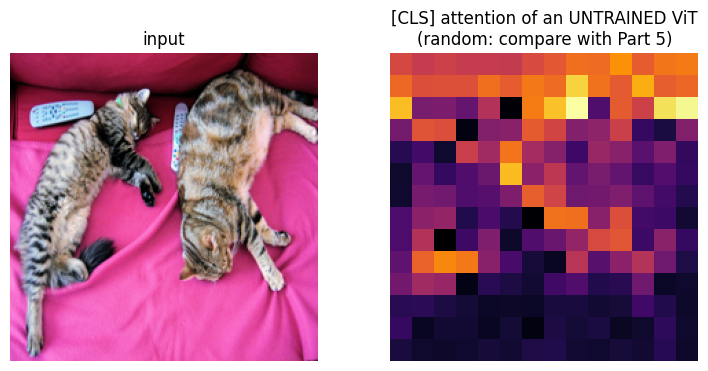

In [ ]:
weights = vit_base.blocks[-1].attention.attention_weights()   # attention of the last block: (1, 12 heads, 197, 197)
cls_to_patches = weights[0, :, 0, 1:]                      # row 0 = what [CLS] looks at; columns 1: = the 196 patches -> (12, 196)
cls_to_patches = cls_to_patches.mean(dim=0)                # average over the 12 heads: (196,)
cls_map = cls_to_patches.reshape(14, 14)                   # put the 196 numbers back on the 14x14 patch grid

plt.figure(figsize=(9, 4))                                 # figure
plt.subplot(1, 2, 1)                                       # left panel
plt.imshow(tensor_to_image(batch[0]))                      # the input image
plt.title("input")                                         # title
plt.axis("off")                                            # no axis
plt.subplot(1, 2, 2)                                       # right panel
plt.imshow(cls_map, cmap="inferno")                        # where [CLS] looks
plt.title("[CLS] attention of an UNTRAINED ViT\n(random: compare with Part 5)")   # title
plt.axis("off")                                            # no axis
plt.show()                                                 # display
del vit_base                                               # delete the big model to free memory

### Why VLMs care about the number of image tokens
Attention compares **every token with every other token**, so the cost grows like **N²**. Doubling the image resolution gives **4× more tokens** and **16× more attention work**. That is why real VLMs **compress** the visual tokens (Part 6).

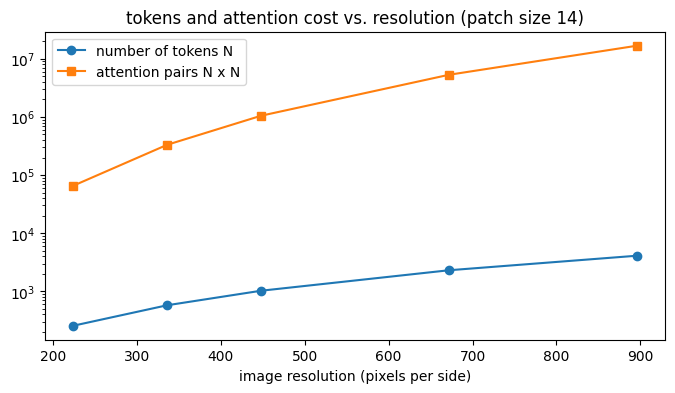

In [ ]:
resolutions = [224, 336, 448, 672, 896]                    # image sizes (pixels per side)
num_tokens = []                                            # list for N
attention_pairs = []                                       # list for N*N
for r in resolutions:                                      # for every resolution
    n = (r // 14) ** 2                                     # number of patches with patch size 14
    num_tokens.append(n)                                   # store N
    attention_pairs.append(n * n)                          # store N^2 (number of query-key pairs)

plt.figure(figsize=(8, 4))                                 # figure
plt.plot(resolutions, num_tokens, "o-", label="number of tokens N")          # N grows like resolution^2
plt.plot(resolutions, attention_pairs, "s-", label="attention pairs N x N")  # N^2 grows like resolution^4
plt.yscale("log")                                          # log scale, because the numbers grow so fast
plt.xlabel("image resolution (pixels per side)")           # x label
plt.legend()                                               # show the legend
plt.title("tokens and attention cost vs. resolution (patch size 14)")   # title
plt.show()                                                 # display

### Concept check (Part 2)
1. A 336×336 image with patch size 14 gives how many tokens? (24 × 24 = **576**, the number LLaVA-1.5 uses.)
2. Why does the transformer block keep the shape `(B, N, D)` unchanged?
3. Without position embeddings, what could a ViT not tell apart?

---
# Part 3: The text side and our toy dataset (1:00 – 1:15)

## 3.1 Tokenization
Text is cut into **tokens** (words or pieces of words). Each token gets an integer **id**, and each id is looked up in an **embedding table** of shape `(V, D)`. Here is GPT-2's tokenizer:

In [ ]:
from transformers import AutoTokenizer                     # Hugging Face's tokenizer loader

gpt2_tokenizer = AutoTokenizer.from_pretrained("gpt2")     # download GPT-2's tokenizer
sentence = "A Vision-Language Model reads images and text: unbelievably cool!"   # an example sentence
token_ids = gpt2_tokenizer(sentence)["input_ids"]          # sentence -> list of integer ids
token_texts = gpt2_tokenizer.convert_ids_to_tokens(token_ids)   # ids -> the text piece of every token
print(len(sentence), "characters ->", len(token_ids), "tokens")   # how many tokens we got
for piece, number in zip(token_texts, token_ids):          # go over the tokens one by one
    print(f"{number:>6}   {piece}")                        # print the id and the text piece (Ġ means "space before")

embedding_table = nn.Embedding(gpt2_tokenizer.vocab_size, 64)   # a table with one 64-long vector per token id
ids_tensor = torch.tensor([token_ids])                     # ids as a tensor with a batch dimension: (1, T)
vectors = embedding_table(ids_tensor)                      # look up the vector of every id: (1, T, 64)
print("ids:", ids_tensor.shape, "-> vectors:", vectors.shape)   # (1, T) -> (1, T, 64)

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

65 characters -> 13 tokens
    32   A
 19009   ĠVision
    12   -
 32065   Language
  9104   ĠModel
  9743   Ġreads
  4263   Ġimages
   290   Ġand
  2420   Ġtext
    25   :
 48943   Ġunbelievably
  3608   Ġcool
     0   !
ids: torch.Size([1, 13]) -> vectors: torch.Size([1, 13, 64])


## 3.2 Our toy dataset: "Shapes World"

To **train VLMs from scratch in a few minutes**, we make our own images. Each 64×64 image has one shape with four properties:
* **shape**: circle / square / triangle
* **color**: red / green / blue / yellow / purple
* **size**: small / large
* **position**: left / right / top / bottom

That gives 3 × 5 × 2 × 4 = **120 different captions**, such as *"a small red circle on the left"*.

train images: torch.Size([6000, 3, 64, 64])
test images: torch.Size([600, 3, 64, 64])


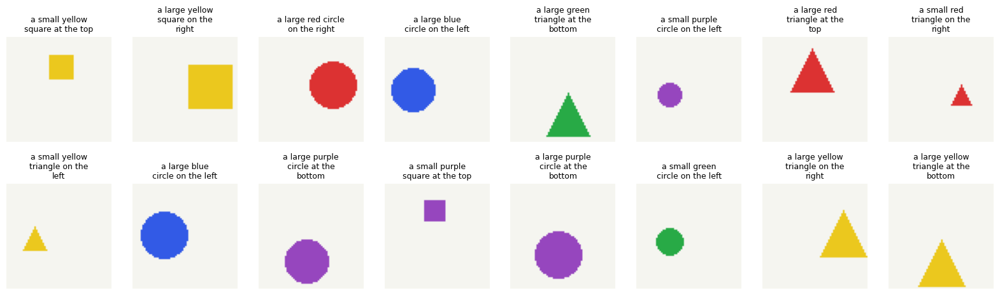

In [ ]:
SHAPES = ["circle", "square", "triangle"]                  # possible shapes
COLORS = {"red": (220, 50, 50), "green": (40, 170, 70), "blue": (50, 90, 230), "yellow": (235, 200, 30), "purple": (150, 70, 190)}   # color name -> RGB
SIZES = {"small": 7, "large": 13}                          # size name -> half-width in pixels
POSITIONS = {"left": (18, 32), "right": (46, 32), "top": (32, 18), "bottom": (32, 46)}   # position name -> (x, y) of the center
POSITION_WORDS = {"left": "on the left", "right": "on the right", "top": "at the top", "bottom": "at the bottom"}   # words used in captions


def draw_shape(shape, color, size, position):              # draw one 64x64 picture
    image = Image.new("RGB", (64, 64), (245, 245, 240))    # empty light-gray canvas
    pen = ImageDraw.Draw(image)                            # a "pen" that draws on the canvas
    cx, cy = POSITIONS[position]                           # center of the shape
    cx = cx + random.randint(-3, 3)                        # move it a little left/right at random
    cy = cy + random.randint(-3, 3)                        # move it a little up/down at random
    r = SIZES[size] + random.randint(-1, 1)                # half-width, plus or minus 1 pixel
    fill = COLORS[color]                                   # the RGB color
    box = [cx - r, cy - r, cx + r, cy + r]                 # bounding box: left, top, right, bottom
    if shape == "circle":                                  # if it is a circle ...
        pen.ellipse(box, fill=fill)                        # ... draw a filled circle
    elif shape == "square":                                # if it is a square ...
        pen.rectangle(box, fill=fill)                      # ... draw a filled square
    else:                                                  # otherwise it is a triangle ...
        pen.polygon([(cx, cy - r), (cx - r, cy + r), (cx + r, cy + r)], fill=fill)   # ... top, bottom-left, bottom-right corners
    return image                                           # return the picture


def make_caption(a):                                       # a = dictionary with the 4 properties
    return "a " + a["size"] + " " + a["color"] + " " + a["shape"] + " " + POSITION_WORDS[a["position"]]   # e.g. "a small red circle on the left"


def make_dataset(n):                                       # make n random (image, properties) pairs
    images = []                                            # list of images
    attributes = []                                        # list of property dictionaries
    for _ in range(n):                                     # repeat n times
        a = {                                              # pick random properties
            "shape": random.choice(SHAPES),                # random shape
            "color": random.choice(list(COLORS)),          # random color
            "size": random.choice(list(SIZES)),            # random size
            "position": random.choice(list(POSITIONS)),    # random position
        }
        picture = draw_shape(a["shape"], a["color"], a["size"], a["position"])   # draw it
        images.append(np.array(picture))                   # store the picture as numbers (64, 64, 3)
        attributes.append(a)                               # store its properties
    images = torch.tensor(np.stack(images))                # one big tensor: (n, 64, 64, 3), values 0..255
    images = images.permute(0, 3, 1, 2)                    # channels first: (n, 3, 64, 64)
    return images, attributes                              # return both


def to_model_input(uint8_images):                          # 0..255 integers -> floats between -1 and 1
    x = uint8_images.float() / 255.0                       # 0..1
    x = (x - 0.5) / 0.5                                    # -1..1
    return x                                               # return


train_images, train_attributes = make_dataset(6000)        # 6000 training examples
test_images, test_attributes = make_dataset(600)           # 600 test examples (never used for training)
print("train images:", train_images.shape)                 # (6000, 3, 64, 64)
print("test images:", test_images.shape)                   # (600, 3, 64, 64)

plt.figure(figsize=(20, 5.5))                              # wide figure
for i in range(16):                                        # show 16 examples
    plt.subplot(2, 8, i + 1)                               # 2 rows of 8 panels
    plt.imshow(train_images[i].permute(1, 2, 0))           # matplotlib needs (H, W, 3)
    caption = make_caption(train_attributes[i])            # its caption
    plt.title("\n".join(textwrap.wrap(caption, 18)), fontsize=9)   # caption as title, wrapped into short lines
    plt.axis("off")                                        # no axis
plt.show()                                                 # display

## 3.3 A word-level tokenizer for our toy world
Our world is tiny, so **one token per word** is enough. We add 4 **special tokens**:
`<pad>` (padding), `<bos>` (begin), `<eos>` (end), `<sep>` (separates a question from its answer, used in Part 6).

In [ ]:
QUESTIONS = {                                              # question type -> question text (used in Part 6)
    "color": "what color is the shape",                    # asks for the color
    "shape": "what shape is it",                           # asks for the shape
    "size": "how big is the shape",                        # asks for the size
    "position": "where is the shape",                      # asks for the position
    "caption": "describe the image",                       # asks for the full caption
}

all_attributes = []                                        # list of ALL 120 possible property combinations
for s in SHAPES:                                           # every shape
    for c in COLORS:                                       # every color
        for z in SIZES:                                    # every size
            for p in POSITIONS:                            # every position
                all_attributes.append({"shape": s, "color": c, "size": z, "position": p})   # store the combination
all_captions = []                                          # list of the 120 captions
for a in all_attributes:                                   # for every combination
    all_captions.append(make_caption(a))                   # make its caption

words = set()                                              # a set keeps each word only once
for text in all_captions + list(QUESTIONS.values()):       # all captions and all questions
    for word in text.split():                              # split the text into words
        words.add(word)                                    # add the word to the set
vocab = ["<pad>", "<bos>", "<eos>", "<sep>"] + sorted(words)   # the full vocabulary: specials first, then words
word_to_id = {}                                            # dictionary: word -> id
for i, word in enumerate(vocab):                           # go over the vocabulary
    word_to_id[word] = i                                   # the id of a word is its position in the list
PAD = word_to_id["<pad>"]                                  # id of <pad>
BOS = word_to_id["<bos>"]                                  # id of <bos>
EOS = word_to_id["<eos>"]                                  # id of <eos>
SEP = word_to_id["<sep>"]                                  # id of <sep>
V = len(vocab)                                             # vocabulary size


def encode(text):                                          # text -> list of ids
    ids = []                                               # empty list
    for word in text.split():                              # for every word
        ids.append(word_to_id[word])                       # look up its id
    return ids                                             # return the list


def decode(ids):                                           # list of ids -> text
    return " ".join(vocab[i] for i in ids)                 # look up every word and join with spaces


def caption_to_ids(caption):                               # caption -> ids with <bos> and <eos>
    return [BOS] + encode(caption) + [EOS]                 # e.g. <bos> a small red circle on the left <eos>


train_caption_ids = torch.tensor([caption_to_ids(make_caption(a)) for a in train_attributes])   # (6000, 9)
test_caption_ids = torch.tensor([caption_to_ids(make_caption(a)) for a in test_attributes])     # (600, 9)
all_caption_ids = torch.tensor([caption_to_ids(c) for c in all_captions])                       # (120, 9)
CAPTION_LEN = train_caption_ids.shape[1]                   # every caption has the same length (9 tokens)

print("vocabulary size V =", V)                            # number of different tokens
print("vocabulary:", vocab)                                # all tokens
print("number of different captions:", len(all_captions))  # 120
print("example caption:", make_caption(train_attributes[0]))   # a caption as text
print("as ids:", train_caption_ids[0].tolist())            # the same caption as ids
print("decoded back:", decode(train_caption_ids[0].tolist()))   # and back to text

vocabulary size V = 32
vocabulary: ['<pad>', '<bos>', '<eos>', '<sep>', 'a', 'at', 'big', 'blue', 'bottom', 'circle', 'color', 'describe', 'green', 'how', 'image', 'is', 'it', 'large', 'left', 'on', 'purple', 'red', 'right', 'shape', 'small', 'square', 'the', 'top', 'triangle', 'what', 'where', 'yellow']
number of different captions: 120
example caption: a small yellow square at the top
as ids: [1, 4, 24, 31, 25, 5, 26, 27, 2]
decoded back: <bos> a small yellow square at the top <eos>


## 3.4 The text encoder (for CLIP)
A small transformer with a **causal mask**, like CLIP's text encoder. The sentence vector is the output at the **last token** (`<eos>`). Because of the causal mask, the last token is the only one that has seen the whole sentence.

In [ ]:
class TextEncoder(nn.Module):                              # turns a sentence into one vector
    def __init__(self, vocab_size, seq_len, dim, depth, heads):   # settings: vocabulary size, sentence length, token size, blocks, heads
        super().__init__()                                 # set up PyTorch's module machinery
        self.token_embedding = nn.Embedding(vocab_size, dim)   # table: token id -> vector of size dim
        self.position_embedding = nn.Parameter(torch.randn(1, seq_len, dim) * 0.02)   # one vector per position
        self.blocks = nn.ModuleList()                      # list of transformer blocks
        for _ in range(depth):                             # create `depth` blocks
            self.blocks.append(TransformerBlock(dim, heads))   # add one block
        self.final_norm = nn.LayerNorm(dim)                # last normalization

    def forward(self, ids):                                # ids: (B, T)
        T = ids.shape[1]                                   # sentence length
        x = self.token_embedding(ids)                      # look up the word vectors: (B, T, dim)
        x = x + self.position_embedding[:, :T]             # add position information
        mask = torch.tril(torch.ones(T, T, device=ids.device))   # causal mask: word t only sees words 0..t
        for block in self.blocks:                          # go through the blocks
            x = block(x, mask=mask)                        # (B, T, dim)
        x = self.final_norm(x)                             # final normalization
        return x[:, -1]                                    # output of the LAST token (<eos>): (B, dim)


text_encoder = TextEncoder(vocab_size=V, seq_len=CAPTION_LEN, dim=128, depth=2, heads=4)   # a small text encoder
sentence_vectors = text_encoder(train_caption_ids[:4])     # encode 4 captions
print("ids:", train_caption_ids[:4].shape)                 # (4, 9)
print("sentence vectors:", sentence_vectors.shape)         # (4, 128): one vector per caption

ids: torch.Size([4, 9])
sentence vectors: torch.Size([4, 128])


---
# Part 4: CLIP from scratch (1:15 – 1:45)

**CLIP** trains an **image encoder** and a **text encoder** together on (image, caption) pairs.

**The idea:** in a batch of `B` pairs, image *i* should be **most similar to caption *i*** and less similar to the other captions, and the same in the other direction. This is a **B-way classification in both directions** (the "contrastive" or InfoNCE loss):

$$S_{ij} = \frac{\text{cos}(\text{image}_i, \text{text}_j)}{\tau}, \qquad \mathcal{L} = \tfrac{1}{2}\big[\text{CE}(S, \text{diagonal}) + \text{CE}(S^\top, \text{diagonal})\big]$$

`τ` is the **temperature**, and it is learned. Goal: the similarity matrix should be **bright on the diagonal**.

chance level log(8): 2.0794415416798357
loss for random vectors: 4.045547962188721
loss when text = image: 1.3977166418044362e-05


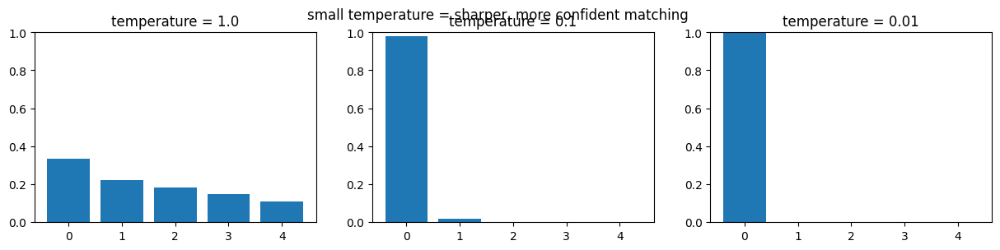

In [ ]:
def clip_loss(logits):                                     # logits: (B, B) similarities (rows = images, columns = texts)
    B = logits.shape[0]                                    # batch size
    targets = torch.arange(B, device=logits.device)        # the correct column for row i is column i: [0, 1, ..., B-1]
    loss_images = F.cross_entropy(logits, targets)         # every image must pick its own caption
    loss_texts = F.cross_entropy(logits.T, targets)        # every caption must pick its own image
    return (loss_images + loss_texts) / 2                  # average of both directions


img_vecs = F.normalize(torch.randn(8, 64), dim=-1)         # 8 random image vectors with length 1
txt_vecs = F.normalize(torch.randn(8, 64), dim=-1)         # 8 random text vectors with length 1
print("chance level log(8):", math.log(8))                 # the loss when guessing
print("loss for random vectors:", clip_loss(img_vecs @ txt_vecs.T / 0.07).item())    # high
print("loss when text = image:", clip_loss(img_vecs @ img_vecs.T / 0.07).item())     # close to 0

similarities = torch.tensor([0.9, 0.5, 0.3, 0.1, -0.2])   # similarities of one image to 5 captions
plt.figure(figsize=(15, 3))                                # wide figure
for i, tau in enumerate([1.0, 0.1, 0.01]):                 # three temperatures
    plt.subplot(1, 3, i + 1)                               # panel i+1
    plt.bar(range(5), torch.softmax(similarities / tau, dim=0).numpy())   # softmax at this temperature
    plt.title("temperature = " + str(tau))                 # title
    plt.ylim(0, 1)                                         # same y range for all panels
plt.suptitle("small temperature = sharper, more confident matching")   # overall title
plt.show()                                                 # display

## 4.1 The Mini-CLIP model
* Image encoder: our `ViT` (64×64 images, patches of 8 → **64 patches + [CLS]**, D = 128, 4 blocks)
* Text encoder: our `TextEncoder` (D = 128, 2 blocks)
* Two **linear projections** into a shared 64-d space, then **normalize** to length 1
* A learnable **logit scale** = 1/τ, starting at 1/0.07 as in CLIP

In [ ]:
class MiniCLIP(nn.Module):                                 # image encoder + text encoder
    def __init__(self):                                    # build the two encoders and the projections
        super().__init__()                                 # set up PyTorch's module machinery
        self.image_encoder = ViT(image_size=64, patch_size=8, dim=128, depth=4, heads=4)   # 64 patches + [CLS]
        self.text_encoder = TextEncoder(vocab_size=V, seq_len=CAPTION_LEN, dim=128, depth=2, heads=4)   # small text transformer
        self.image_projection = nn.Linear(128, 64)         # image features -> shared 64-d space
        self.text_projection = nn.Linear(128, 64)          # text features -> shared 64-d space
        self.logit_scale = nn.Parameter(torch.tensor(math.log(1 / 0.07)))   # learnable log(1/temperature)

    def encode_image(self, images):                        # images: (B, 3, 64, 64)
        x = self.image_encoder(images)                     # (B, 65, 128)
        x = x[:, 0]                                        # keep only the [CLS] token: (B, 128)
        x = self.image_projection(x)                       # (B, 64)
        x = F.normalize(x, dim=-1)                         # make every vector length 1
        return x                                           # (B, 64)

    def encode_text(self, ids):                            # ids: (B, T)
        x = self.text_encoder(ids)                         # (B, 128)
        x = self.text_projection(x)                        # (B, 64)
        x = F.normalize(x, dim=-1)                         # make every vector length 1
        return x                                           # (B, 64)

    def forward(self, images, ids):                        # a batch of matching pairs
        image_vectors = self.encode_image(images)          # (B, 64)
        text_vectors = self.encode_text(ids)               # (B, 64)
        similarity = image_vectors @ text_vectors.T        # cosine similarity of every image with every text: (B, B)
        logits = similarity * self.logit_scale.exp()       # divide by the temperature (= multiply by 1/τ)
        return logits                                      # (B, B)


clip_model = MiniCLIP().to(device)                         # create the model and move it to the GPU/CPU
n_params = sum(p.numel() for p in clip_model.parameters()) # count the learnable numbers
print("Mini-CLIP parameters:", n_params)                   # about 1.2 million (real CLIP ViT-B/16: 150 million)

four_images = to_model_input(train_images[:4]).to(device)  # 4 images: (4, 3, 64, 64)
four_captions = train_caption_ids[:4].to(device)           # their captions: (4, 9)
with torch.no_grad():                                      # no training here
    print("image vectors:", clip_model.encode_image(four_images).shape)   # (4, 64)
    print("text vectors:", clip_model.encode_text(four_captions).shape)   # (4, 64)
    print("logits:", clip_model(four_images, four_captions).shape)        # (4, 4)

Mini-CLIP parameters: 1245057
image vectors: torch.Size([4, 64])
text vectors: torch.Size([4, 64])
logits: torch.Size([4, 4])


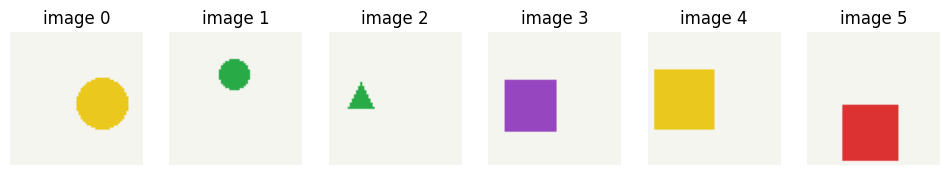

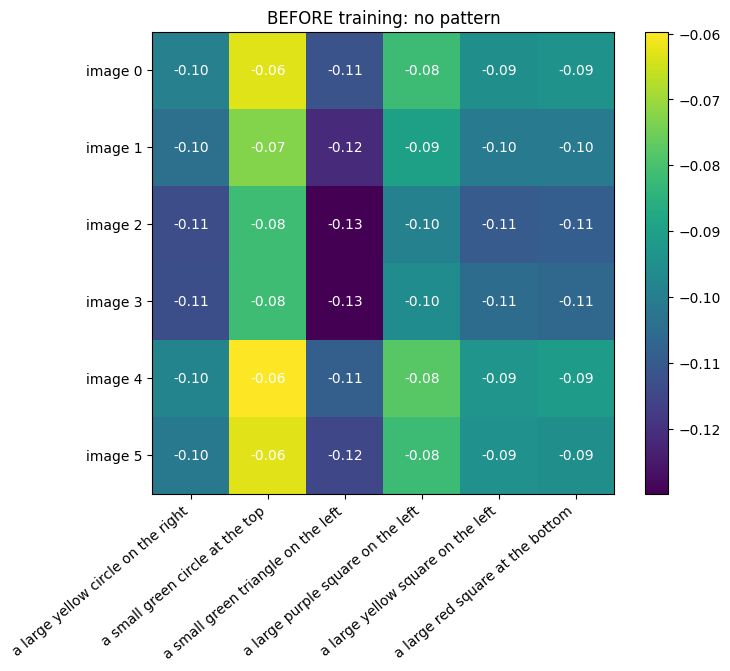

In [ ]:
demo_indices = []                                          # 6 test examples with 6 DIFFERENT captions (for the plots)
seen_captions = []                                         # captions we already picked
for i in range(len(test_attributes)):                      # go over the test set
    caption = make_caption(test_attributes[i])             # caption of example i
    if caption not in seen_captions:                       # if we do not have this caption yet ...
        demo_indices.append(i)                             # ... pick this example
        seen_captions.append(caption)                      # ... and remember its caption
    if len(demo_indices) == 6:                             # stop when we have 6
        break                                              # leave the loop


def show_similarity(model, title):                         # plot the 6x6 image-caption similarity matrix
    model.eval()                                           # evaluation mode
    with torch.no_grad():                                  # no gradients needed
        image_vectors = model.encode_image(to_model_input(test_images[demo_indices]).to(device))   # (6, 64)
        text_vectors = model.encode_text(test_caption_ids[demo_indices].to(device))                # (6, 64)
    similarity = (image_vectors @ text_vectors.T).cpu()    # (6, 6) cosine similarities

    plt.figure(figsize=(12, 2))                            # strip of the 6 images
    for k in range(6):                                     # for every image
        plt.subplot(1, 6, k + 1)                           # panel k+1
        plt.imshow(test_images[demo_indices[k]].permute(1, 2, 0))   # draw the image
        plt.title("image " + str(k))                       # its number
        plt.axis("off")                                    # no axis
    plt.show()                                             # display

    plt.figure(figsize=(8, 6))                             # the matrix
    plt.imshow(similarity, cmap="viridis")                 # colors = similarity
    plt.yticks(range(6), ["image " + str(k) for k in range(6)])   # row labels
    plt.xticks(range(6), seen_captions, rotation=40, ha="right")  # column labels = captions
    for r in range(6):                                     # for every row
        for c in range(6):                                 # for every column
            plt.text(c, r, f"{similarity[r, c]:.2f}", ha="center", va="center", color="white")   # write the number
    plt.colorbar()                                         # color scale
    plt.title(title)                                       # title
    plt.show()                                             # display


show_similarity(clip_model, "BEFORE training: no pattern")  # look at the untrained model

## 4.2 Training Mini-CLIP
This takes about 1 minute on a T4 GPU and a few minutes on CPU. **A good moment for a short break.**

**Zero-shot accuracy:** to classify a test image, we compare it with **all 120 possible captions** and pick the most similar one. The model was never trained as a classifier!

In [ ]:
def zero_shot_predict(model, uint8_images):                # predict the caption of every image
    model.eval()                                           # evaluation mode
    with torch.no_grad():                                  # no gradients needed
        text_vectors = model.encode_text(all_caption_ids.to(device))   # vectors of all 120 captions: (120, 64)
        image_vectors = model.encode_image(to_model_input(uint8_images).to(device))   # (n, 64)
        similarity = image_vectors @ text_vectors.T        # (n, 120)
        predictions = similarity.argmax(dim=1)             # index of the most similar caption for every image: (n,)
    return predictions.cpu()                               # return on the CPU


test_true_index = []                                       # the index (0..119) of the true caption of every test image
for a in test_attributes:                                  # for every test example
    test_true_index.append(all_captions.index(make_caption(a)))   # find its caption in the list of 120
test_true_index = torch.tensor(test_true_index)            # as a tensor: (600,)

optimizer = torch.optim.Adam(clip_model.parameters(), lr=5e-4)   # Adam optimizer, learning rate 0.0005
batch_size = 128                                           # pairs per training step
num_epochs = 20                                            # how many times we go over the training data
losses = []                                                # loss of every step (for the plot)
test_accuracies = []                                       # test accuracy after every epoch
start_time = time.time()                                   # start the clock

for epoch in range(num_epochs):                            # go over the training data num_epochs times
    clip_model.train()                                     # training mode
    order = torch.randperm(len(train_images))              # random order of the training examples
    for start in range(0, len(train_images) - batch_size + 1, batch_size):   # step through the data in batches
        idx = order[start:start + batch_size]              # indices of this batch
        batch_images = to_model_input(train_images[idx]).to(device)   # images: (128, 3, 64, 64)
        batch_ids = train_caption_ids[idx].to(device)      # captions: (128, 9)
        logits = clip_model(batch_images, batch_ids)       # similarity matrix: (128, 128)
        loss = clip_loss(logits)                           # contrastive loss
        optimizer.zero_grad()                              # clear the old gradients
        loss.backward()                                    # compute new gradients
        optimizer.step()                                   # update the weights
        losses.append(loss.item())                         # remember the loss
    predictions = zero_shot_predict(clip_model, test_images)   # zero-shot predictions on the test set
    accuracy = (predictions == test_true_index).float().mean().item()   # fraction of correct captions
    test_accuracies.append(accuracy)                       # remember it
    print(f"epoch {epoch + 1:2d} | loss {np.mean(losses[-46:]):.3f} | zero-shot test accuracy {accuracy:.2f} | {time.time() - start_time:.0f}s")   # progress

epoch  1 | loss 4.386 | zero-shot test accuracy 0.11 | 116s
epoch  2 | loss 2.523 | zero-shot test accuracy 0.13 | 201s
epoch  3 | loss 2.288 | zero-shot test accuracy 0.17 | 286s
epoch  4 | loss 2.260 | zero-shot test accuracy 0.14 | 360s
epoch  5 | loss 2.209 | zero-shot test accuracy 0.19 | 434s
epoch  6 | loss 2.135 | zero-shot test accuracy 0.20 | 505s
epoch  7 | loss 2.022 | zero-shot test accuracy 0.22 | 586s
epoch  8 | loss 1.944 | zero-shot test accuracy 0.26 | 657s
epoch  9 | loss 1.692 | zero-shot test accuracy 0.48 | 733s
epoch 10 | loss 1.352 | zero-shot test accuracy 0.63 | 805s
epoch 11 | loss 1.085 | zero-shot test accuracy 0.67 | 880s
epoch 12 | loss 1.003 | zero-shot test accuracy 0.84 | 946s
epoch 13 | loss 0.833 | zero-shot test accuracy 0.91 | 1010s
epoch 14 | loss 0.745 | zero-shot test accuracy 0.94 | 1075s
epoch 15 | loss 0.718 | zero-shot test accuracy 0.95 | 1148s
epoch 16 | loss 0.688 | zero-shot test accuracy 0.94 | 1213s
epoch 17 | loss 0.655 | zero-shot te

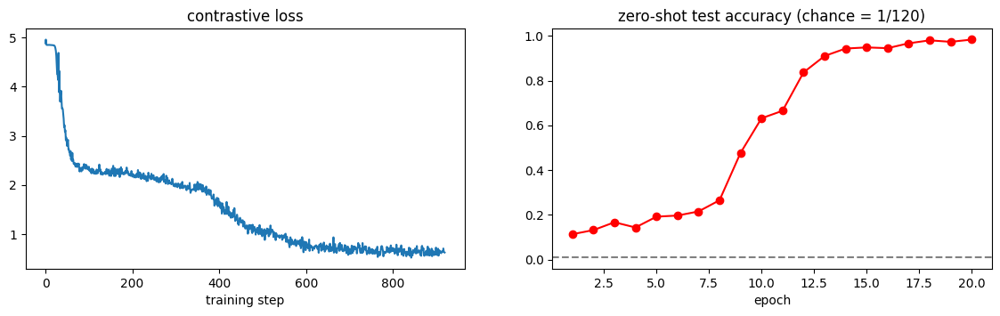

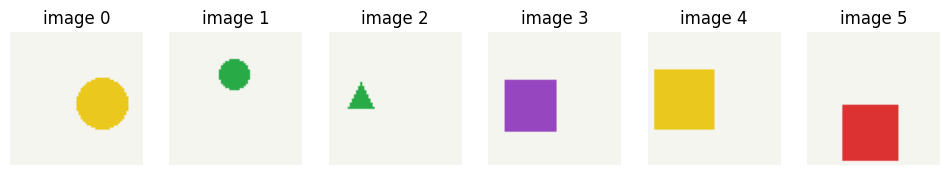

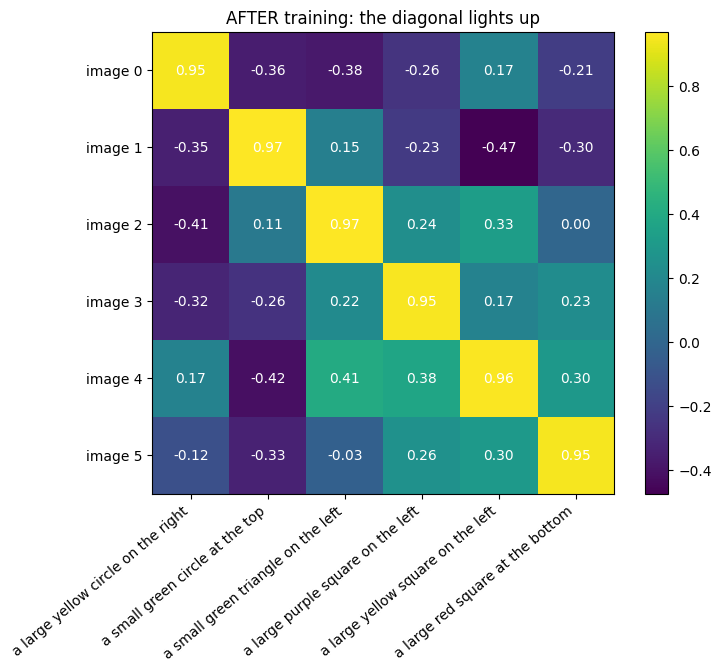

In [ ]:
plt.figure(figsize=(14, 3.5))                              # wide figure
plt.subplot(1, 2, 1)                                       # left panel
plt.plot(losses)                                           # loss of every step
plt.title("contrastive loss")                              # title
plt.xlabel("training step")                                # x label
plt.subplot(1, 2, 2)                                       # right panel
plt.plot(range(1, num_epochs + 1), test_accuracies, "o-", color="red")   # accuracy after every epoch
plt.axhline(1 / 120, linestyle="--", color="gray")         # chance level: 1 out of 120
plt.title("zero-shot test accuracy (chance = 1/120)")      # title
plt.xlabel("epoch")                                        # x label
plt.show()                                                 # display

show_similarity(clip_model, "AFTER training: the diagonal lights up")   # look at the trained model

## 4.3 What can Mini-CLIP do?
### (a) Zero-shot classification

exact caption accuracy: 0.983 (chance: 0.008)
shape      accuracy: 0.983
color      accuracy: 1.000
size       accuracy: 1.000
position   accuracy: 1.000


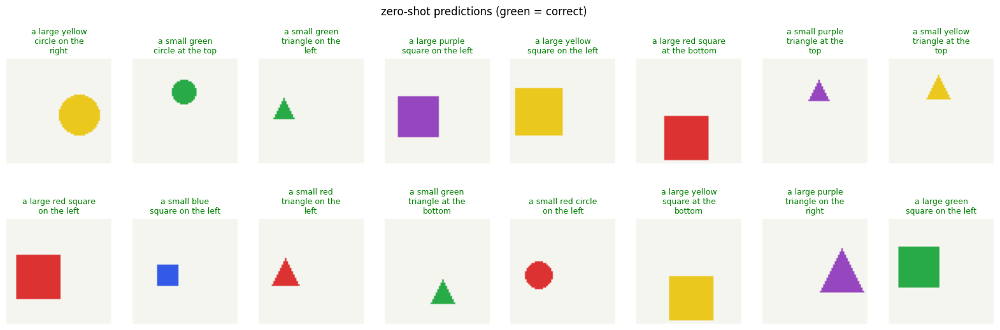

In [ ]:
predictions = zero_shot_predict(clip_model, test_images)   # predicted caption index for every test image
accuracy = (predictions == test_true_index).float().mean().item()   # fraction exactly right
print("exact caption accuracy:", round(accuracy, 3), "(chance: 0.008)")   # print it

for prop in ["shape", "color", "size", "position"]:        # accuracy for every single property
    correct = 0                                            # counter
    for i in range(len(test_attributes)):                  # for every test image
        predicted = all_attributes[predictions[i]][prop]   # the property in the predicted caption
        if predicted == test_attributes[i][prop]:          # is it right?
            correct = correct + 1                          # count it
    print(f"{prop:<10s} accuracy: {correct / len(test_attributes):.3f}")   # print the property accuracy

plt.figure(figsize=(20, 6))                                # wide figure
for i in range(16):                                        # 16 test images
    plt.subplot(2, 8, i + 1)                               # panel i+1
    plt.imshow(test_images[i].permute(1, 2, 0))            # draw the image
    predicted_caption = all_captions[predictions[i]]       # the predicted caption
    is_correct = predictions[i] == test_true_index[i]      # was it right?
    color = "green" if is_correct else "red"               # green = right, red = wrong
    plt.title("\n".join(textwrap.wrap(predicted_caption, 18)), color=color, fontsize=9)   # show the prediction
    plt.axis("off")                                        # no axis
plt.suptitle("zero-shot predictions (green = correct)")    # overall title
plt.show()                                                 # display

### (b) Text → image search
Type a caption and find the most similar test images. This is a tiny **image search engine**.

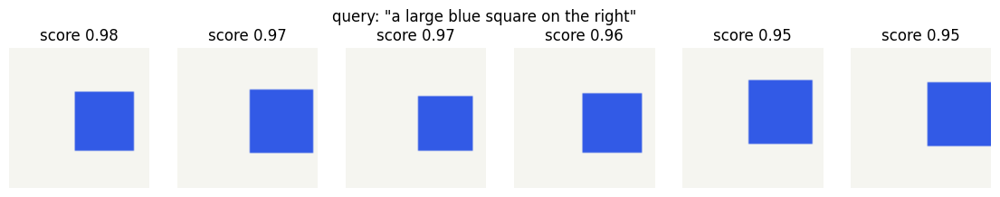

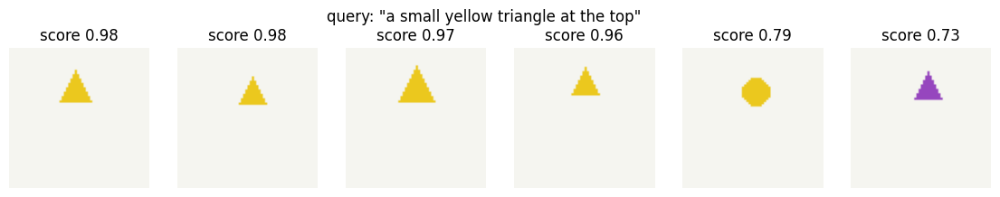

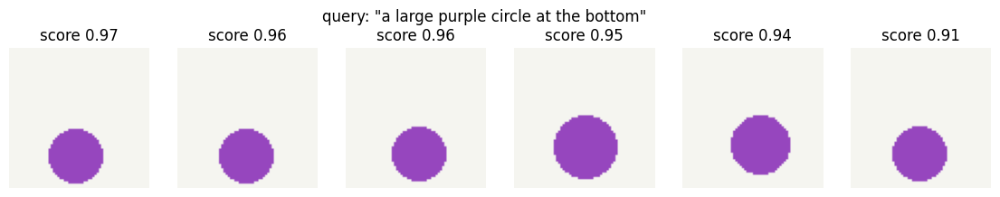

In [ ]:
clip_model.eval()                                          # evaluation mode
with torch.no_grad():                                      # no gradients needed
    test_image_vectors = clip_model.encode_image(to_model_input(test_images).to(device))   # vectors of all test images: (600, 64)

queries = ["a large blue square on the right", "a small yellow triangle at the top", "a large purple circle at the bottom"]   # search texts
for query in queries:                                      # for every search text
    query_ids = torch.tensor([caption_to_ids(query)]).to(device)   # text -> ids: (1, 9)
    with torch.no_grad():                                  # no gradients needed
        query_vector = clip_model.encode_text(query_ids)   # (1, 64)
    scores = (test_image_vectors @ query_vector.T)[:, 0]   # similarity of every test image to the query: (600,)
    best = scores.argsort(descending=True)[:6]             # indices of the 6 best images
    plt.figure(figsize=(14, 2.5))                          # a row of results
    for k in range(6):                                     # for each of the top 6
        plt.subplot(1, 6, k + 1)                           # panel k+1
        plt.imshow(test_images[best[k]].permute(1, 2, 0))  # draw the image
        plt.title(f"score {scores[best[k]]:.2f}")          # its similarity
        plt.axis("off")                                    # no axis
    plt.suptitle('query: "' + query + '"')                 # the query as title
    plt.show()                                             # display

### (c) What does the embedding space look like?
We squeeze the 64-d image vectors into 2-D with **PCA** and color the points by each property.

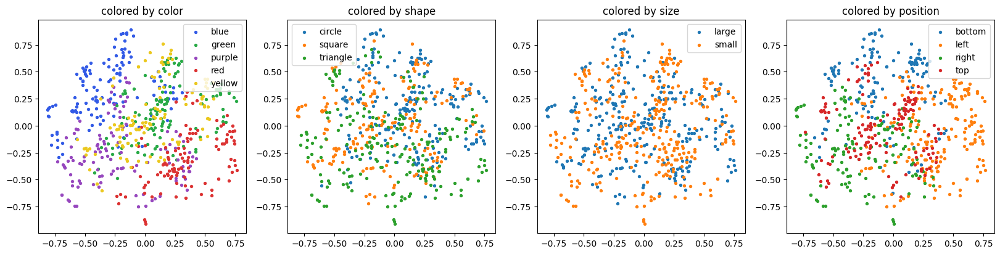

In [ ]:
from sklearn.decomposition import PCA                      # PCA from scikit-learn

points = PCA(n_components=2).fit_transform(test_image_vectors.cpu().numpy())   # (600, 64) -> (600, 2)

plt.figure(figsize=(20, 4.5))                              # wide figure
for panel, prop in enumerate(["color", "shape", "size", "position"]):   # one panel per property
    plt.subplot(1, 4, panel + 1)                           # panel
    values = sorted(set(a[prop] for a in test_attributes)) # the possible values, e.g. red, green, ...
    for value in values:                                   # one group of dots per value
        chosen = [i for i in range(len(test_attributes)) if test_attributes[i][prop] == value]   # examples with this value
        if prop == "color":                                # in the color panel ...
            dot_color = np.array(COLORS[value]) / 255      # ... draw dots in the shape's real color (0..1 for matplotlib)
        else:                                              # in the other panels ...
            dot_color = None                               # ... let matplotlib pick the colors
        plt.scatter(points[chosen, 0], points[chosen, 1], s=8, label=value, color=dot_color)   # draw them
    plt.legend()                                           # legend
    plt.title("colored by " + prop)                        # title
plt.show()                                                 # display

### (d) Where does the trained ViT look?
Attention of the **[CLS] token** to the 8×8 patches in the last block (averaged over heads). Compare with the untrained ViT in Part 2.

attention weights: torch.Size([8, 4, 65, 65])


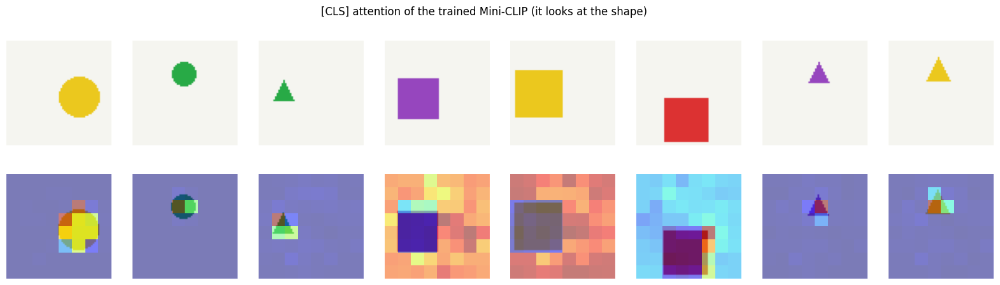

In [ ]:
with torch.no_grad():                                      # no gradients needed
    clip_model.encode_image(to_model_input(test_images[:8]).to(device))   # run 8 test images (this stores the attention weights)
weights = clip_model.image_encoder.blocks[-1].attention.attention_weights()   # last block: (8, 4 heads, 65, 65)
print("attention weights:", weights.shape)                 # print the shape
cls_maps = weights[:, :, 0, 1:]                            # what [CLS] looks at, patches only: (8, 4, 64)
cls_maps = cls_maps.mean(dim=1)                            # average over heads: (8, 64)
cls_maps = cls_maps.reshape(8, 8, 8).cpu()                 # back on the 8x8 patch grid: (8, 8, 8)

plt.figure(figsize=(20, 5))                                # wide figure
for i in range(8):                                         # for every image
    plt.subplot(2, 8, i + 1)                               # top row
    plt.imshow(test_images[i].permute(1, 2, 0))            # the image
    plt.axis("off")                                        # no axis
    plt.subplot(2, 8, i + 9)                               # bottom row
    plt.imshow(test_images[i].permute(1, 2, 0))            # the image again ...
    plt.imshow(cls_maps[i], cmap="jet", alpha=0.5, extent=(0, 64, 64, 0))   # ... with the attention map on top
    plt.axis("off")                                        # no axis
plt.suptitle("[CLS] attention of the trained Mini-CLIP (it looks at the shape)")   # title
plt.show()                                                 # display

### Concept check (Part 4)
1. Why do we normalize the vectors to length 1 before comparing them?
2. CLIP used huge batches (32,768). Why does a bigger batch help a contrastive loss?
3. In our toy world, the same caption can appear twice in a batch. Why is that a problem for this loss?

---
# Part 5: Pretrained CLIP under the microscope (1:45 – 2:05)

Now we load OpenAI's **CLIP ViT-B/16** (150M parameters, trained on 400 million image-text pairs). Its image encoder is **the same ViT we wrote in Part 2**, just much bigger and trained.

In [ ]:
from transformers import CLIPModel, CLIPProcessor          # CLIP model and its preprocessing

clip_name = "openai/clip-vit-base-patch16"                 # name of the model on Hugging Face
real_clip = CLIPModel.from_pretrained(clip_name, attn_implementation="eager").to(device)   # download; "eager" lets us read attention weights
real_clip.eval()                                           # evaluation mode
clip_processor = CLIPProcessor.from_pretrained(clip_name)  # resizes/normalizes images and tokenizes text
n_params = sum(p.numel() for p in real_clip.parameters())  # count parameters
print("CLIP ViT-B/16 parameters:", round(n_params / 1e6), "million")   # about 150M

embeddings = real_clip.vision_model.embeddings             # the first part of CLIP's ViT
print("patch embedding:   ", embeddings.patch_embedding)   # Conv2d(3, 768, kernel 16, stride 16) = our patchify + Linear
print("[CLS] token:       ", embeddings.class_embedding.shape)   # (768,) = our cls_token
print("position embedding:", embeddings.position_embedding)      # 197 positions = 196 patches + CLS
print("number of blocks:  ", len(real_clip.vision_model.encoder.layers))   # 12 = our 12 TransformerBlocks

config.json:   0%|          | 0.00/4.10k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  599MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  599MB            

...

vocab.json:   0%|          | 0.00/961k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

CLIP ViT-B/16 parameters: 150 million
patch embedding:    Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16), bias=False)
[CLS] token:        torch.Size([768])
position embedding: Embedding(197, 768)
number of blocks:   12


## 5.1 Zero-shot classification of real photos

pixel_values: torch.Size([6, 3, 224, 224])
input_ids: torch.Size([9, 8])


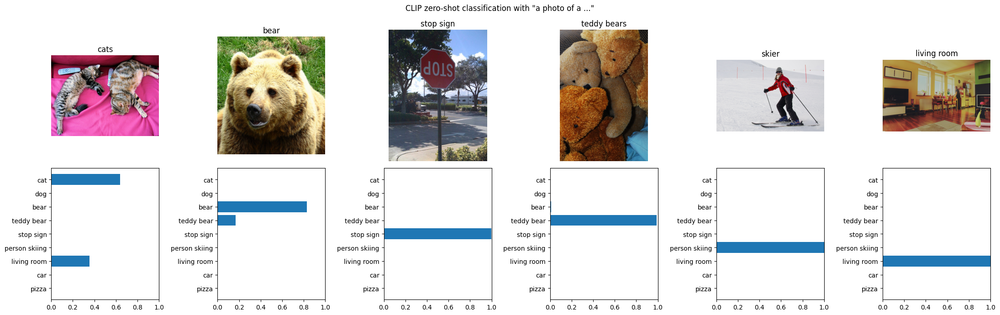

In [ ]:
labels = ["cat", "dog", "bear", "teddy bear", "stop sign", "person skiing", "living room", "car", "pizza"]   # possible classes
prompts = []                                               # one sentence per class
for label in labels:                                       # for every class
    prompts.append("a photo of a " + label)                # e.g. "a photo of a cat"
names = list(images)                                       # names of our 6 photos
photo_list = [images[n] for n in names]                    # the 6 photos in a list

inputs = clip_processor(text=prompts, images=photo_list, return_tensors="pt", padding=True).to(device)   # preprocess images and text
print("pixel_values:", inputs["pixel_values"].shape)       # (6, 3, 224, 224)
print("input_ids:", inputs["input_ids"].shape)             # (9, number of text tokens)
with torch.no_grad():                                      # no gradients needed
    outputs = real_clip(**inputs)                          # run CLIP
probabilities = outputs.logits_per_image.softmax(dim=-1).cpu()   # (6 images, 9 labels): probabilities per image

plt.figure(figsize=(22, 7))                                # wide figure
for i in range(len(names)):                                # for every photo
    plt.subplot(2, len(names), i + 1)                      # top row
    plt.imshow(photo_list[i])                              # the photo
    plt.title(names[i])                                    # its name
    plt.axis("off")                                        # no axis
    plt.subplot(2, len(names), len(names) + i + 1)         # bottom row
    plt.barh(labels, probabilities[i].numpy())             # horizontal bars: probability of every label
    plt.xlim(0, 1)                                         # probabilities go from 0 to 1
    plt.gca().invert_yaxis()                               # first label at the top
plt.suptitle('CLIP zero-shot classification with "a photo of a ..."')   # title
plt.tight_layout()                                         # avoid overlapping text
plt.show()                                                 # display

## 5.2 Prompt engineering matters
CLIP learned from web captions, not single words, so wrapping the label in a sentence usually helps.

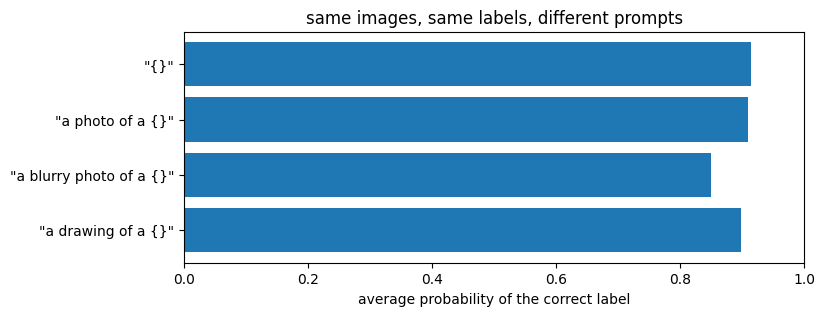

In [ ]:
true_label = {"cats": "cat", "bear": "bear", "stop sign": "stop sign", "teddy bears": "teddy bear", "skier": "person skiing", "living room": "living room"}   # correct label of each photo
templates = ["{}", "a photo of a {}", "a blurry photo of a {}", "a drawing of a {}"]   # different ways to write the prompt

scores = []                                                # one score per template
for template in templates:                                 # try every template
    texts = [template.format(label) for label in labels]   # fill the template with every label
    inputs = clip_processor(text=texts, images=photo_list, return_tensors="pt", padding=True).to(device)   # preprocess
    with torch.no_grad():                                  # no gradients needed
        probs = real_clip(**inputs).logits_per_image.softmax(dim=-1).cpu()   # (6, 9)
    total = 0                                              # sum of the correct-label probabilities
    for i, name in enumerate(names):                       # for every photo
        total = total + probs[i, labels.index(true_label[name])].item()   # probability of its correct label
    scores.append(total / len(names))                      # average over the photos

plt.figure(figsize=(8, 3))                                 # figure
plt.barh(['"' + t + '"' for t in templates], scores)       # one bar per template
plt.gca().invert_yaxis()                                   # first template at the top
plt.xlim(0, 1)                                             # 0..1
plt.xlabel("average probability of the correct label")     # x label
plt.title("same images, same labels, different prompts")   # title
plt.show()                                                 # display

## 5.3 Matching real photos with captions

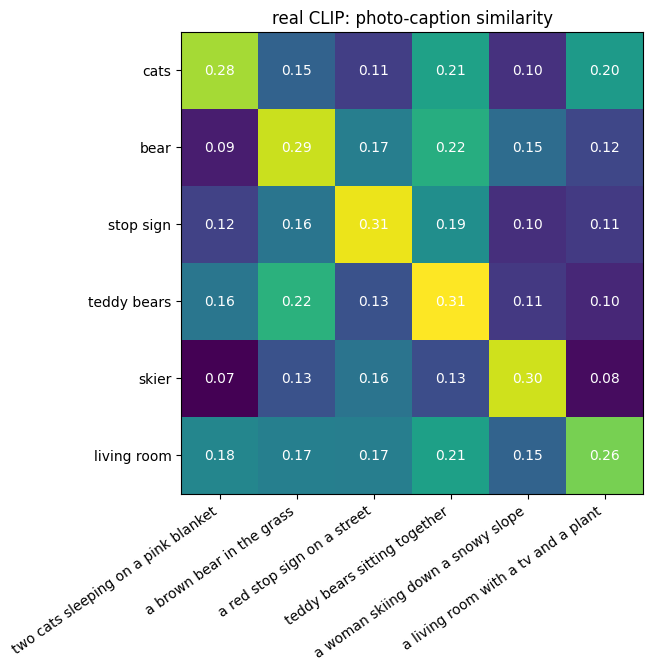

In [ ]:
captions = ["two cats sleeping on a pink blanket", "a brown bear in the grass", "a red stop sign on a street",   # captions for photos 1-3
            "teddy bears sitting together", "a woman skiing down a snowy slope", "a living room with a tv and a plant"]   # one caption per photo
inputs = clip_processor(text=captions, images=photo_list, return_tensors="pt", padding=True).to(device)   # preprocess
with torch.no_grad():                                      # no gradients needed
    outputs = real_clip(**inputs)                          # run CLIP
similarity = (outputs.image_embeds @ outputs.text_embeds.T).cpu()   # cosine similarities (the embeds have length 1): (6, 6)

plt.figure(figsize=(9, 6))                                 # figure
plt.imshow(similarity, cmap="viridis")                     # draw the matrix
plt.yticks(range(6), names)                                # rows = photos
plt.xticks(range(6), captions, rotation=35, ha="right")    # columns = captions
for r in range(6):                                         # every row
    for c in range(6):                                     # every column
        plt.text(c, r, f"{similarity[r, c]:.2f}", ha="center", va="center", color="white")   # write the number
plt.title("real CLIP: photo-caption similarity")           # title
plt.show()                                                 # display

## 5.4 Looking inside CLIP

**(a) Patch filters.** Each of the 768 rows of the patch-embedding weight can be reshaped into a small 3×16×16 image. The trained ViT learned **edge, color and stripe detectors**.

patch filters: torch.Size([768, 3, 16, 16])


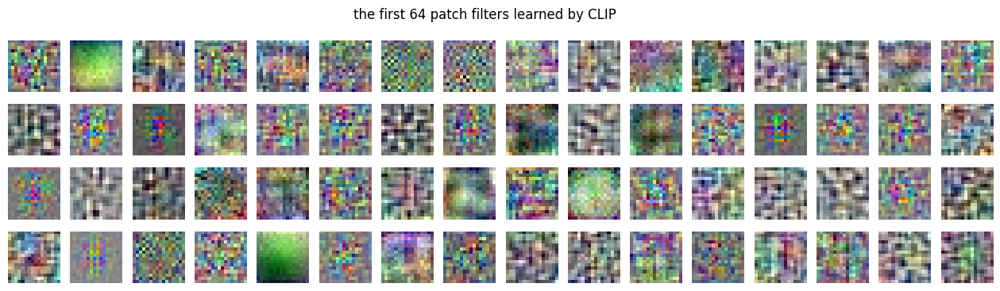

In [ ]:
filters = real_clip.vision_model.embeddings.patch_embedding.weight.detach().cpu()   # (768, 3, 16, 16)
print("patch filters:", filters.shape)                     # print the shape

plt.figure(figsize=(16, 4))                                # figure
for i in range(64):                                        # show the first 64 filters
    f = filters[i].permute(1, 2, 0)                        # (16, 16, 3) for plotting
    f = (f - f.min()) / (f.max() - f.min())                # stretch the values to 0..1 so we can see them
    plt.subplot(4, 16, i + 1)                              # 4 rows of 16 panels
    plt.imshow(f.numpy())                                  # draw the filter
    plt.axis("off")                                        # no axis
plt.suptitle("the first 64 patch filters learned by CLIP")   # title
plt.show()                                                 # display

**(b) Learned position embeddings.** CLIP's 196 patch-position vectors are simply learned, and nobody told the model that patches form a 2-D grid. Yet each position becomes most similar to **its own row and its own column**: CLIP learned the 2-D layout by itself.

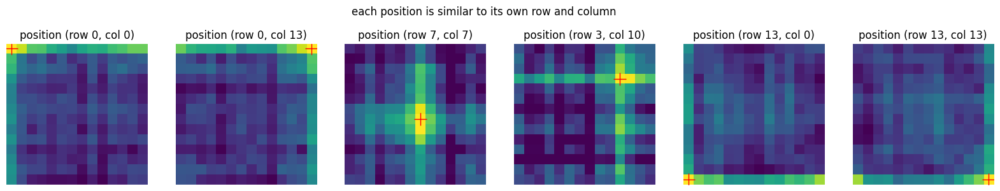

In [ ]:
pos = real_clip.vision_model.embeddings.position_embedding.weight[1:].detach().cpu()   # 196 patch positions (skip CLS): (196, 768)
pos = pos - pos.mean(dim=0)                                # remove the part shared by all positions (it hides the pattern)
pos = F.normalize(pos, dim=-1)                             # length 1, so dot product = cosine similarity
pos_similarity = pos @ pos.T                               # similarity of every position with every position: (196, 196)

chosen = [(0, 0), (0, 13), (7, 7), (3, 10), (13, 0), (13, 13)]   # some (row, column) positions to look at
plt.figure(figsize=(20, 3.5))                              # wide figure
for k, (r, c) in enumerate(chosen):                        # for every chosen position
    plt.subplot(1, len(chosen), k + 1)                     # panel k+1
    sim_map = pos_similarity[r * 14 + c].reshape(14, 14)   # its similarity to all positions, on the 14x14 grid
    plt.imshow(sim_map, cmap="viridis", vmin=-0.2, vmax=0.6)   # draw it
    plt.plot(c, r, "r+", markersize=14)                    # mark the chosen position with a red +
    plt.title(f"position (row {r}, col {c})")              # title
    plt.axis("off")                                        # no axis
plt.suptitle("each position is similar to its own row and column")   # overall title
plt.show()                                                 # display

**(c) Attention rollout.** To see which patches end up in the [CLS] token, we **multiply the attention maps of all 12 layers** (adding the identity matrix to account for the residual connections).

number of layers: 12
attention of one layer: torch.Size([6, 12, 197, 197])


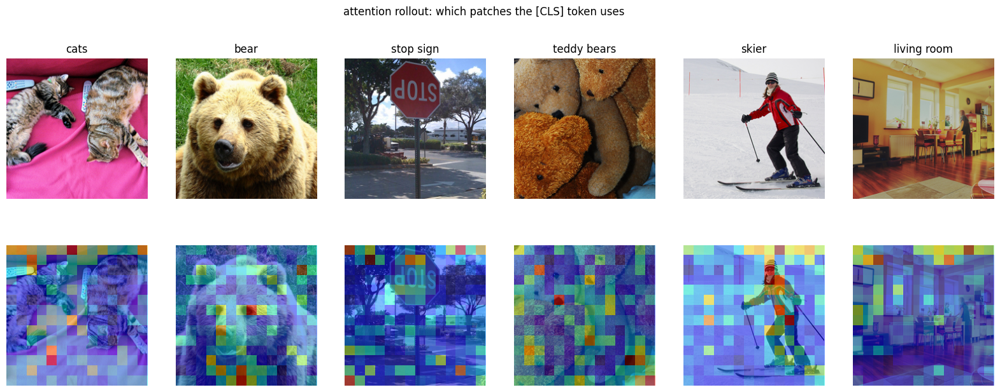

In [ ]:
pixel_values = clip_processor(images=photo_list, return_tensors="pt")["pixel_values"].to(device)   # (6, 3, 224, 224)
with torch.no_grad():                                      # no gradients needed
    vision_outputs = real_clip.vision_model(pixel_values=pixel_values, output_attentions=True)   # also return attention weights
print("number of layers:", len(vision_outputs.attentions))         # 12
print("attention of one layer:", vision_outputs.attentions[0].shape)   # (6 images, 12 heads, 197, 197)

rollout = torch.eye(197, device=device)                    # start with the identity matrix
for layer_attention in vision_outputs.attentions:          # go through the layers, first to last
    A = layer_attention.mean(dim=1)                        # average over the heads: (6, 197, 197)
    A = A + torch.eye(197, device=device)                  # add the identity for the residual connection
    A = A / A.sum(dim=-1, keepdim=True)                    # make every row sum to 1 again
    rollout = A @ rollout                                  # combine with the layers before
cls_rollout = rollout[:, 0, 1:].reshape(-1, 14, 14).cpu()  # what [CLS] collects from each patch: (6, 14, 14)

plt.figure(figsize=(20, 7))                                # wide figure
for i in range(len(names)):                                # for every photo
    plt.subplot(2, len(names), i + 1)                      # top row
    plt.imshow(tensor_to_image(pixel_values[i]))           # the (cropped) photo
    plt.title(names[i])                                    # name
    plt.axis("off")                                        # no axis
    plt.subplot(2, len(names), len(names) + i + 1)         # bottom row
    plt.imshow(tensor_to_image(pixel_values[i]))           # the photo again ...
    plt.imshow(cls_rollout[i], cmap="jet", alpha=0.5, extent=(0, 224, 224, 0))   # ... with the rollout map on top
    plt.axis("off")                                        # no axis
plt.suptitle("attention rollout: which patches the [CLS] token uses")   # title
plt.show()                                                 # display

del real_clip                                              # delete the model to free memory for the next parts

---
# Part 6: A generative VLM from scratch, LLaVA-style (2:05 – 2:35)

CLIP can only **score** image-text pairs. To **write text** about an image, LLaVA uses a simple recipe:

1. Encode the image with a **vision encoder** (kept frozen) → patch features
2. Map them to the language model's size with a small **projector** (MLP) → "visual tokens"
3. **Put the visual tokens in front of the text tokens** and run a normal **language model**
4. Train with **next-word prediction, only on the answer words**

```
[img 0] [img 1] ... [img 64]   <bos> what color is the shape <sep>   red <eos>
 \___ 65 visual tokens ___/    \______ question (no loss) ______/   \_ answer: loss here _/
```

We build exactly this on Shapes World, **reusing our trained Mini-CLIP image encoder** as the frozen vision encoder.

| | Real LLaVA-1.5 | Our Mini-LLaVA |
|---|---|---|
| vision encoder | CLIP ViT-L/14 (frozen) | our Mini-CLIP ViT (frozen) |
| visual tokens | 576 | 65 |
| projector | 2-layer MLP | 2-layer MLP |
| language model | Vicuna-7B (pretrained) | TinyGPT, 4 blocks, trained from scratch |

In [ ]:
def get_answer(a, question_type):                          # the correct answer for one image and one question type
    if question_type == "caption":                         # for "describe the image" ...
        return make_caption(a)                             # ... the answer is the full caption
    return a[question_type]                                # otherwise just the property, e.g. "red"


def make_rows(attributes):                                 # one training row per (image, question)
    rows = []                                              # empty list
    for i in range(len(attributes)):                       # for every image
        for question_type in QUESTIONS:                    # for every question type
            question_ids = [BOS] + encode(QUESTIONS[question_type]) + [SEP]   # <bos> question words <sep>
            answer_ids = encode(get_answer(attributes[i], question_type)) + [EOS]   # answer words <eos>
            rows.append((i, question_ids, answer_ids))     # store (image index, question, answer)
    return rows                                            # return the list


train_rows = make_rows(train_attributes)                   # 6000 images x 5 questions = 30000 rows
TEXT_LEN = 0                                               # length of the longest text
for _, question_ids, answer_ids in train_rows:             # for every row
    TEXT_LEN = max(TEXT_LEN, len(question_ids) + len(answer_ids))   # keep the maximum
print("training rows:", len(train_rows))                   # 30000
print("longest text:", TEXT_LEN, "tokens")                 # 13


def make_batch(rows):                                      # turn some rows into padded tensors
    ids = torch.full((len(rows), TEXT_LEN), PAD)           # start with all <pad>: (B, TEXT_LEN)
    labels = torch.full((len(rows), TEXT_LEN), -100)       # -100 means "no loss at this position"
    image_indices = []                                     # which image belongs to each row
    for b in range(len(rows)):                             # for every row
        image_index, question_ids, answer_ids = rows[b]    # unpack the row
        text = question_ids + answer_ids                   # the full text: question then answer
        ids[b, :len(text)] = torch.tensor(text)            # write the text into the row
        start = len(question_ids)                          # position where the answer starts
        labels[b, start:len(text)] = torch.tensor(answer_ids)   # we only want a loss on the answer
        image_indices.append(image_index)                  # remember the image
    return torch.tensor(image_indices), ids, labels        # return the three tensors


image_indices, ids, labels = make_batch(train_rows[:5])    # a small example batch
for b in range(5):                                         # show the 5 rows
    print("text:  ", decode(ids[b].tolist()))              # the text with padding
    print("labels:", labels[b].tolist())                   # -100 everywhere except the answer

training rows: 30000
longest text: 13 tokens
text:   <bos> what color is the shape <sep> yellow <eos> <pad> <pad> <pad> <pad>
labels: [-100, -100, -100, -100, -100, -100, -100, 31, 2, -100, -100, -100, -100]
text:   <bos> what shape is it <sep> square <eos> <pad> <pad> <pad> <pad> <pad>
labels: [-100, -100, -100, -100, -100, -100, 25, 2, -100, -100, -100, -100, -100]
text:   <bos> how big is the shape <sep> small <eos> <pad> <pad> <pad> <pad>
labels: [-100, -100, -100, -100, -100, -100, -100, 24, 2, -100, -100, -100, -100]
text:   <bos> where is the shape <sep> top <eos> <pad> <pad> <pad> <pad> <pad>
labels: [-100, -100, -100, -100, -100, -100, 27, 2, -100, -100, -100, -100, -100]
text:   <bos> describe the image <sep> a small yellow square at the top <eos>
labels: [-100, -100, -100, -100, -100, 4, 24, 31, 25, 5, 26, 27, 2]


In [ ]:
class TinyGPT(nn.Module):                                  # a very small GPT-style language model
    def __init__(self, vocab_size, dim, depth, heads, max_len):   # settings: vocabulary size, token size, blocks, heads, longest sequence
        super().__init__()                                 # set up PyTorch's module machinery
        self.token_embedding = nn.Embedding(vocab_size, dim)   # word id -> vector
        self.position_embedding = nn.Parameter(torch.randn(1, max_len, dim) * 0.02)   # one vector per position
        self.blocks = nn.ModuleList()                      # list of transformer blocks
        for _ in range(depth):                             # create `depth` blocks
            self.blocks.append(TransformerBlock(dim, heads))   # add one block
        self.final_norm = nn.LayerNorm(dim)                # last normalization
        self.to_vocab = nn.Linear(dim, vocab_size)         # vector -> one score per word in the vocabulary

    def forward(self, embeddings):                         # takes VECTORS (not ids), so we can mix image and text tokens: (B, L, dim)
        L = embeddings.shape[1]                            # sequence length
        x = embeddings + self.position_embedding[:, :L]    # add position information
        mask = torch.tril(torch.ones(L, L, device=x.device))   # causal mask: no looking at future tokens
        for block in self.blocks:                          # go through the blocks
            x = block(x, mask=mask)                        # (B, L, dim)
        x = self.final_norm(x)                             # final normalization
        return self.to_vocab(x)                            # scores for the next word at every position: (B, L, V)


class MiniLLaVA(nn.Module):                                # vision encoder + projector + language model
    def __init__(self, vision_encoder):                    # vision_encoder = our trained Mini-CLIP ViT
        super().__init__()                                 # set up PyTorch's module machinery
        self.vision_encoder = vision_encoder               # the trained Mini-CLIP ViT
        for p in self.vision_encoder.parameters():         # for every weight of the vision encoder ...
            p.requires_grad = False                        # ... freeze it (it will not be trained)
        self.projector = nn.Sequential(                    # small MLP: vision features -> language-model vectors
            nn.Linear(128, 128),                           # first layer
            nn.GELU(),                                     # non-linearity
            nn.Linear(128, 128),                           # second layer
        )
        self.language_model = TinyGPT(vocab_size=V, dim=128, depth=4, heads=4, max_len=128)   # the language model
        self.num_image_tokens = 65                         # 64 patches + [CLS]

    def forward(self, images, ids):                        # images: (B, 3, 64, 64)  ids: (B, T)
        with torch.no_grad():                              # the vision encoder is frozen
            features = self.vision_encoder(images)         # image features: (B, 65, 128)
        image_tokens = self.projector(features)            # visual tokens: (B, 65, 128)
        text_tokens = self.language_model.token_embedding(ids)   # word vectors: (B, T, 128)
        sequence = torch.cat([image_tokens, text_tokens], dim=1)   # image first, then text: (B, 65 + T, 128)
        scores = self.language_model(sequence)             # next-word scores at every position: (B, 65 + T, V)
        return scores[:, self.num_image_tokens:]           # keep only the text positions: (B, T, V)


mini_vlm = MiniLLaVA(clip_model.image_encoder).to(device)  # build the VLM around our trained image encoder
trainable = sum(p.numel() for p in mini_vlm.parameters() if p.requires_grad)   # count trainable weights
print("trainable parameters (projector + language model):", trainable)   # about 0.8 million

with torch.no_grad():                                      # just a shape check
    example_scores = mini_vlm(to_model_input(train_images[image_indices]).to(device), ids.to(device))   # run 5 rows
print("images:", train_images[image_indices].shape)        # (5, 3, 64, 64)
print("text ids:", ids.shape)                              # (5, 13)
print("sequence inside the LM: 65 image tokens + 13 text tokens = 78 tokens")   # explanation
print("output scores:", example_scores.shape)              # (5, 13, V)

trainable parameters (projector + language model): 850976
images: torch.Size([5, 3, 64, 64])
text ids: torch.Size([5, 13])
sequence inside the LM: 65 image tokens + 13 text tokens = 78 tokens
output scores: torch.Size([5, 13, 32])


### The loss: predict the NEXT word
The scores at position *t* predict the word at position *t + 1*. So we compare `scores[:, :-1]` with `labels[:, 1:]`. Positions with label `-100` (question, padding) are ignored.

epoch 1 | loss 0.2256 | 499s
epoch 2 | loss 0.0094 | 994s
epoch 3 | loss 0.0068 | 1492s
epoch 4 | loss 0.0017 | 1980s


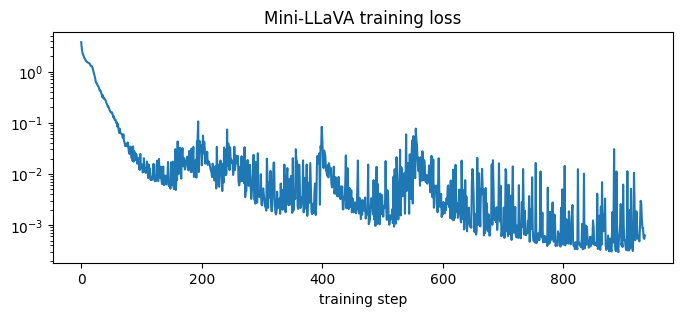

In [ ]:
def next_word_loss(scores, labels):                        # scores: (B, T, V)   labels: (B, T)
    predictions = scores[:, :-1]                           # scores at positions 0..T-2
    targets = labels[:, 1:]                                # the words at positions 1..T-1 (shifted by one)
    predictions = predictions.reshape(-1, V)               # flatten: (B*(T-1), V)
    targets = targets.reshape(-1)                          # flatten: (B*(T-1),)
    return F.cross_entropy(predictions, targets, ignore_index=-100)   # classification loss, skipping -100 positions


trainable_params = [p for p in mini_vlm.parameters() if p.requires_grad]   # only projector + language model
optimizer = torch.optim.Adam(trainable_params, lr=1e-3)    # Adam optimizer
batch_size = 128                                           # rows per step
vlm_losses = []                                            # loss of every step
start_time = time.time()                                   # start the clock

for epoch in range(4):                                     # 4 passes over the data
    mini_vlm.train()                                       # training mode
    random.shuffle(train_rows)                             # shuffle the rows
    for start in range(0, len(train_rows) - batch_size + 1, batch_size):   # step through the rows in batches
        image_indices, batch_ids, batch_labels = make_batch(train_rows[start:start + batch_size])   # build a batch
        batch_images = to_model_input(train_images[image_indices]).to(device)   # the images of this batch
        scores = mini_vlm(batch_images, batch_ids.to(device))   # next-word scores: (128, 13, V)
        loss = next_word_loss(scores, batch_labels.to(device))  # loss on the answer words only
        optimizer.zero_grad()                              # clear old gradients
        loss.backward()                                    # compute gradients
        optimizer.step()                                   # update the weights
        vlm_losses.append(loss.item())                     # remember the loss
    print(f"epoch {epoch + 1} | loss {np.mean(vlm_losses[-234:]):.4f} | {time.time() - start_time:.0f}s")   # progress

plt.figure(figsize=(8, 3))                                 # figure
plt.plot(vlm_losses)                                       # loss curve
plt.yscale("log")                                          # log scale shows the drop better
plt.title("Mini-LLaVA training loss")                      # title
plt.xlabel("training step")                                # x label
plt.show()                                                 # display

## 6.1 Generating answers, one word at a time
Generation is a loop: run the model, take the **most likely next word**, append it, and repeat. This is called **greedy decoding**.

color     correct image: 1.000   wrong image: 0.195
shape     correct image: 0.982   wrong image: 0.332
size      correct image: 1.000   wrong image: 0.507
position  correct image: 1.000   wrong image: 0.228
caption   correct image: 0.982   wrong image: 0.013


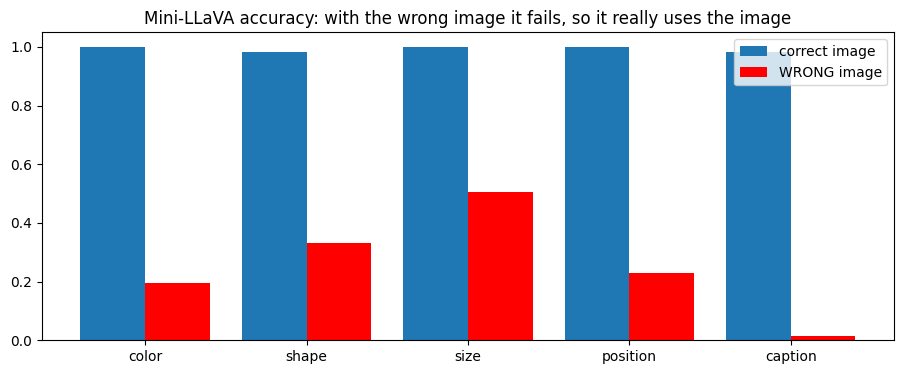

In [ ]:
def generate(model, uint8_images, question, max_new_words=10):   # answer the same question for many images
    model.eval()                                           # evaluation mode
    images = to_model_input(uint8_images).to(device)       # prepare the images: (B, 3, 64, 64)
    B = images.shape[0]                                    # number of images
    prompt = [BOS] + encode(question) + [SEP]              # <bos> question <sep>
    ids = torch.tensor([prompt] * B, device=device)        # the same prompt for every image: (B, prompt length)
    with torch.no_grad():                                  # no gradients needed
        for _ in range(max_new_words):                     # add one word per loop
            scores = model(images, ids)                    # scores at every position: (B, L, V)
            next_word = scores[:, -1].argmax(dim=-1)       # most likely next word at the LAST position: (B,)
            ids = torch.cat([ids, next_word[:, None]], dim=1)   # append it: (B, L + 1)
    answers = []                                           # list of answer strings
    for row in ids[:, len(prompt):].tolist():              # the generated part of every row
        if EOS in row:                                     # if the model wrote <eos> ...
            row = row[:row.index(EOS)]                     # ... cut everything after it
        answers.append(decode(row))                        # ids -> words
    return answers                                         # return all answers


def vlm_accuracy(model, uint8_images, attributes):         # exact-match accuracy for every question type
    results = {}                                           # question type -> accuracy
    for question_type in QUESTIONS:                        # for every question type
        answers = generate(model, uint8_images, QUESTIONS[question_type])   # the model's answers
        correct = 0                                        # counter
        for answer, a in zip(answers, attributes):         # compare with the truth
            if answer == get_answer(a, question_type):     # exact match?
                correct = correct + 1                      # count it
        results[question_type] = correct / len(attributes) # accuracy
    return results                                         # return the dictionary


accuracy_right = vlm_accuracy(mini_vlm, test_images, test_attributes)   # with the correct images
shuffled = test_images[torch.randperm(len(test_images))]   # the same images in a random order (wrong image for each question)
accuracy_wrong = vlm_accuracy(mini_vlm, shuffled, test_attributes)      # with the WRONG images
for question_type in QUESTIONS:                            # print a small table
    print(f"{question_type:<9s} correct image: {accuracy_right[question_type]:.3f}   wrong image: {accuracy_wrong[question_type]:.3f}")   # one line per question type

positions = np.arange(len(QUESTIONS))                      # x positions of the bars
plt.figure(figsize=(11, 4))                                # figure
plt.bar(positions - 0.2, list(accuracy_right.values()), 0.4, label="correct image")   # blue bars
plt.bar(positions + 0.2, list(accuracy_wrong.values()), 0.4, label="WRONG image", color="red")   # red bars
plt.xticks(positions, list(QUESTIONS))                     # question types as labels
plt.ylim(0, 1.05)                                          # y range
plt.legend()                                               # legend
plt.title("Mini-LLaVA accuracy: with the wrong image it fails, so it really uses the image")   # title
plt.show()                                                 # display

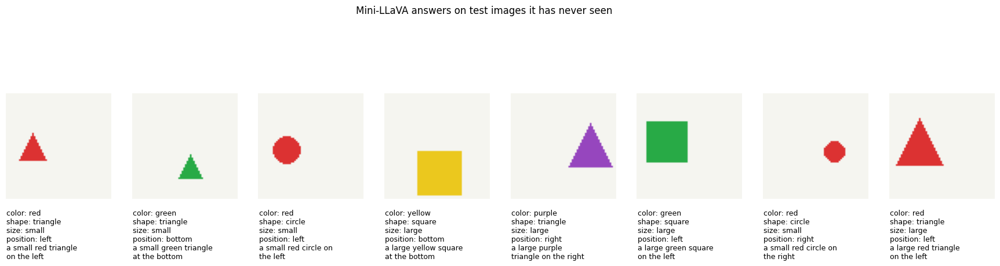

In [ ]:
chosen = list(range(10, 18))                               # 8 test images
answers = {}                                               # question type -> list of 8 answers
for question_type in QUESTIONS:                            # for every question type
    answers[question_type] = generate(mini_vlm, test_images[chosen], QUESTIONS[question_type])   # answer for all 8 images

plt.figure(figsize=(22, 5))                                # wide figure
for k in range(8):                                         # for every image
    plt.subplot(1, 8, k + 1)                               # panel k+1
    plt.imshow(test_images[chosen[k]].permute(1, 2, 0))    # the image
    plt.axis("off")                                        # no axis
    text = ""                                              # build the text below the image
    for question_type in ["color", "shape", "size", "position"]:   # short questions
        text = text + question_type + ": " + answers[question_type][k] + "\n"   # one line per answer
    text = text + "\n".join(textwrap.wrap(answers["caption"][k], 22))   # the generated caption
    plt.text(0, 70, text, fontsize=9, va="top")            # write it under the image
plt.suptitle("Mini-LLaVA answers on test images it has never seen")   # title
plt.show()                                                 # display

## 6.2 Where does the language model look?
When the model is about to answer (at the `<sep>` token), how much attention does it give to each of the 64 visual patch tokens? (Averaged over all blocks and heads.)

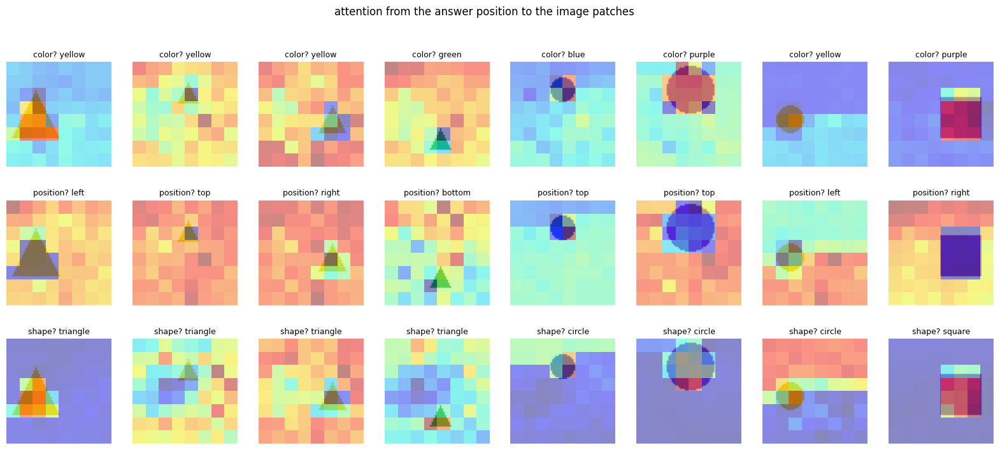

In [ ]:
def answer_attention(model, uint8_images, question):       # attention from <sep> to the 64 patch tokens
    images = to_model_input(uint8_images).to(device)       # prepare the images
    prompt = [BOS] + encode(question) + [SEP]              # the question
    ids = torch.tensor([prompt] * len(images), device=device)   # one prompt per image
    with torch.no_grad():                                  # no gradients needed
        model(images, ids)                                 # run the model (this stores the attention weights)
    maps = []                                              # one map per block
    for block in model.language_model.blocks:              # for every block of the language model
        w = block.attention.attention_weights()            # (B, heads, L, L)
        maps.append(w[:, :, -1, 1:65])                     # row -1 = the <sep> token; columns 1..64 = patch tokens
    maps = torch.stack(maps).mean(dim=(0, 2))              # average over blocks and heads: (B, 64)
    return maps.reshape(-1, 8, 8).cpu()                    # back on the 8x8 patch grid


chosen = list(range(20, 28))                               # 8 test images
plt.figure(figsize=(20, 8))                                # figure
for row, question_type in enumerate(["color", "position", "shape"]):   # 3 questions = 3 rows
    maps = answer_attention(mini_vlm, test_images[chosen], QUESTIONS[question_type])   # (8, 8, 8)
    replies = generate(mini_vlm, test_images[chosen], QUESTIONS[question_type])        # the answers
    for k in range(8):                                     # for every image
        plt.subplot(3, 8, row * 8 + k + 1)                 # panel
        plt.imshow(test_images[chosen[k]].permute(1, 2, 0))   # the image
        plt.imshow(maps[k], cmap="jet", alpha=0.45, extent=(0, 64, 64, 0))   # attention on top
        plt.title(question_type + "? " + replies[k], fontsize=9)   # question and answer
        plt.axis("off")                                    # no axis
plt.suptitle("attention from the answer position to the image patches")   # title
plt.show()                                                 # display

## 6.3 Hallucination in miniature
What does our VLM say about an image with **no shape at all**? It was never taught to say "I don't know", so it answers confidently anyway. Big VLMs do the same; we test SmolVLM in Part 7.

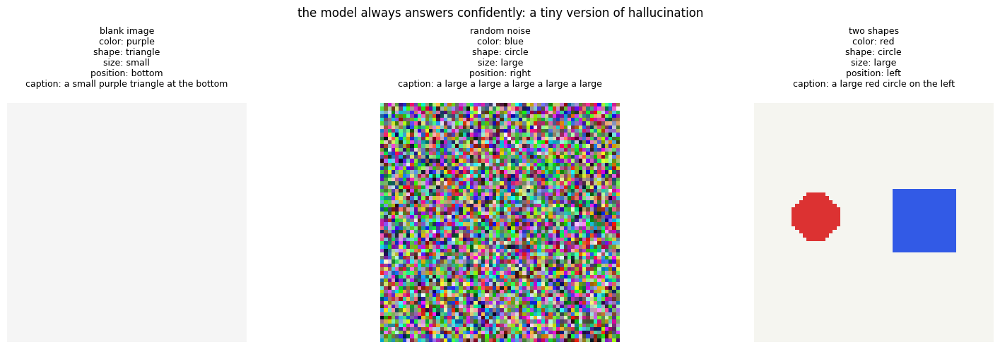

In [ ]:
blank = torch.full((1, 3, 64, 64), 245, dtype=torch.uint8) # an empty light-gray image
noise = torch.randint(0, 256, (1, 3, 64, 64), dtype=torch.uint8)   # random noise
two_shapes = np.minimum(np.array(draw_shape("circle", "red", "small", "left")),   # draw a red circle and ...
                        np.array(draw_shape("square", "blue", "small", "right")))   # two shapes in one image (never seen in training)
two_shapes = torch.tensor(two_shapes).permute(2, 0, 1)[None]   # to a tensor: (1, 3, 64, 64)

strange_images = {"blank image": blank, "random noise": noise, "two shapes": two_shapes}   # our test cases
plt.figure(figsize=(16, 5))                                # figure
for k, name in enumerate(strange_images):                  # for every strange image
    text = name + "\n"                                     # start the title with the name
    for question_type in QUESTIONS:                        # ask every question
        reply = generate(mini_vlm, strange_images[name], QUESTIONS[question_type])[0]   # the model's answer
        text = text + question_type + ": " + reply + "\n"  # add it to the title
    plt.subplot(1, 3, k + 1)                               # panel
    plt.imshow(strange_images[name][0].permute(1, 2, 0))   # the image
    plt.title(text, fontsize=9)                            # all answers
    plt.axis("off")                                        # no axis
plt.suptitle("the model always answers confidently: a tiny version of hallucination")   # title
plt.tight_layout()                                         # avoid overlaps
plt.show()                                                 # display

## 6.4 Other ways to connect vision and language

### (a) Flamingo: gated cross-attention
Flamingo keeps a pretrained language model **frozen** and adds new **cross-attention** layers: the text tokens (queries) look at the visual tokens (keys/values). A **gate that starts at 0** makes each new layer do nothing at first, so the language model is not damaged at the start of training.

text: torch.Size([2, 12, 128])  image: torch.Size([2, 65, 128])  output: torch.Size([2, 12, 128])
cross-attention weights: torch.Size([2, 4, 12, 65])
gate = 0, so output == input? True
gate = 1, output == input? False


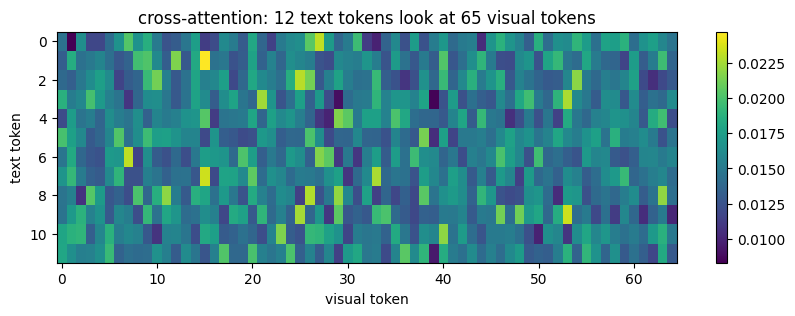

In [ ]:
class GatedCrossAttention(nn.Module):                      # Flamingo-style block
    def __init__(self, dim, heads):                        # settings: token size, number of heads
        super().__init__()                                 # set up PyTorch's module machinery
        self.norm = nn.LayerNorm(dim)                      # normalization of the text tokens
        self.cross_attention = MultiHeadAttention(dim, heads)   # text looks at the image
        self.gate = nn.Parameter(torch.zeros(1))           # the gate, starts at 0

    def forward(self, text, image):                        # text: (B, T, dim)   image: (B, M, dim)
        looked = self.cross_attention(self.norm(text), context=image)   # queries from text, keys/values from image: (B, T, dim)
        return text + torch.tanh(self.gate) * looked       # tanh(0) = 0, so at the start the output equals the input


xattn = GatedCrossAttention(dim=128, heads=4)              # create the block
text_states = torch.randn(2, 12, 128)                      # 12 text tokens inside the language model
image_states = torch.randn(2, 65, 128)                     # 65 visual tokens
out = xattn(text_states, image_states)                     # run it
print("text:", text_states.shape, " image:", image_states.shape, " output:", out.shape)   # output has the TEXT shape
print("cross-attention weights:", xattn.cross_attention.attention_weights().shape)   # (2, 4, 12, 65): text x image, not square
print("gate = 0, so output == input?", torch.allclose(out, text_states))   # True

with torch.no_grad():                                      # change the gate by hand
    xattn.gate.fill_(1.0)                                  # open the gate
print("gate = 1, output == input?", torch.allclose(xattn(text_states, image_states), text_states))   # False

plt.figure(figsize=(10, 3))                                # figure
plt.imshow(xattn.cross_attention.attention_weights()[0].mean(dim=0), aspect="auto")   # average over heads: (12, 65)
plt.xlabel("visual token")                                 # x label
plt.ylabel("text token")                                   # y label
plt.title("cross-attention: 12 text tokens look at 65 visual tokens")   # title
plt.colorbar()                                             # color scale
plt.show()                                                 # display

### (b) BLIP-2 Q-Former / Perceiver Resampler: compress the image
A **small fixed number of learnable "query" vectors** cross-attend to all the image features. The output always has the same small number of tokens, **no matter how big the image is**.

In [ ]:
class QueryResampler(nn.Module):                           # many image tokens -> a few tokens
    def __init__(self, dim, num_queries, heads):           # settings: token size, number of output tokens, heads
        super().__init__()                                 # set up PyTorch's module machinery
        self.queries = nn.Parameter(torch.randn(1, num_queries, dim) * 0.02)   # the learnable query vectors
        self.norm = nn.LayerNorm(dim)                      # normalization
        self.cross_attention = MultiHeadAttention(dim, heads)   # queries look at the image
        self.mlp = nn.Sequential(nn.Linear(dim, 4 * dim), nn.GELU(), nn.Linear(4 * dim, dim))   # small MLP

    def forward(self, image_features):                     # image_features: (B, N, dim), N can be anything
        B = image_features.shape[0]                        # batch size
        q = self.queries.repeat(B, 1, 1)                   # one copy of the queries per image: (B, Q, dim)
        q = q + self.cross_attention(self.norm(q), context=image_features)   # queries read from the image
        q = q + self.mlp(q)                                # process every query
        return q                                           # (B, Q, dim): always Q tokens


resampler = QueryResampler(dim=768, num_queries=32, heads=8)   # 32 output tokens
for n_tokens in [197, 577, 1025]:                          # image features from different resolutions
    features = torch.randn(1, n_tokens, 768)               # fake image features
    with torch.no_grad():                                  # no gradients needed
        compressed = resampler(features)                   # compress
    print(n_tokens, "image tokens ->", compressed.shape[1], "tokens")   # always 32

197 image tokens -> 32 tokens
577 image tokens -> 32 tokens
1025 image tokens -> 32 tokens


### Summary: how real VLMs feed images to a language model
| Model | Connector | Visual tokens per image | How images enter the LM |
|---|---|---|---|
| CLIP | linear projection | 1 vector | (no LM: contrastive) |
| Flamingo | Perceiver Resampler | 64 | gated cross-attention |
| BLIP-2 | Q-Former | 32 | prefix |
| LLaVA-1.5 | 2-layer MLP | 576 | prefix |
| Qwen2-VL | MLP after merging 2×2 tokens | depends on resolution | prefix |
| SmolVLM | pixel-shuffle + linear | 64 per 512px tile | prefix |

**How LLaVA is trained (2 stages):**
1. **Alignment:** freeze the ViT and the LLM; train **only the projector** on image-caption pairs
2. **Instruction tuning:** train **projector + LLM** on conversations about images

---
# Part 7: Pretrained generative VLMs (2:35 – 2:55)

## 7.1 BLIP: an image captioning model

preprocessor_config.json:   0%|          | 0.00/287 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.56k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/506 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

...

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  990MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  990MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/473 [00:00<?, ?it/s]

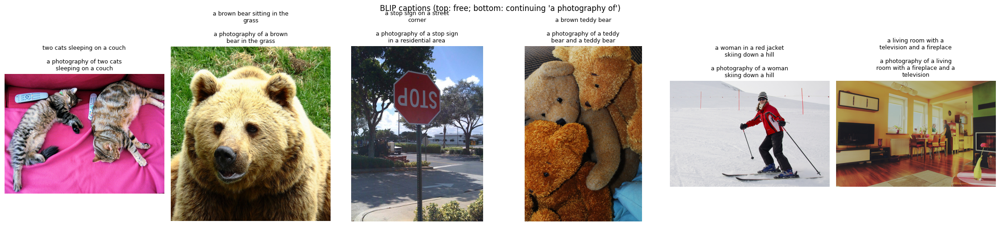

In [ ]:
from transformers import BlipProcessor, BlipForConditionalGeneration   # BLIP model and its preprocessing

blip_name = "Salesforce/blip-image-captioning-base"        # name on Hugging Face
blip_processor = BlipProcessor.from_pretrained(blip_name)  # preprocessing for images and text
blip = BlipForConditionalGeneration.from_pretrained(blip_name).to(device)   # download the model
blip.eval()                                                # evaluation mode


def blip_caption(image, prefix=None, **options):           # caption one image (optionally continue a prefix)
    inputs = blip_processor(images=image, text=prefix, return_tensors="pt").to(device)   # preprocess
    with torch.no_grad():                                  # no gradients needed
        output_ids = blip.generate(**inputs, max_new_tokens=30, **options)   # generate token ids
    return blip_processor.decode(output_ids[0], skip_special_tokens=True)    # ids -> text


plt.figure(figsize=(22, 5))                                # wide figure
for i, name in enumerate(names):                           # for every photo
    caption = blip_caption(images[name])                   # caption from scratch
    caption_with_prefix = blip_caption(images[name], prefix="a photography of")   # caption that continues our prefix
    plt.subplot(1, len(names), i + 1)                      # panel
    plt.imshow(images[name])                               # the photo
    plt.title("\n".join(textwrap.wrap(caption, 28)) + "\n\n" + "\n".join(textwrap.wrap(caption_with_prefix, 28)), fontsize=9)   # both captions
    plt.axis("off")                                        # no axis
plt.suptitle("BLIP captions (top: free; bottom: continuing 'a photography of')")   # title
plt.tight_layout()                                         # avoid overlaps
plt.show()                                                 # display

### Decoding strategies change the output
* **Greedy**: always take the most likely next token (what our Mini-LLaVA does)
* **Beam search**: keep the *k* best partial sentences and pick the best at the end
* **Sampling**: draw the next token at random from the top candidates, which gives more varied captions

In [ ]:
photo = images["skier"]                                    # one photo
print("greedy:              ", blip_caption(photo))                             # most likely token every step
print("beam search (5):     ", blip_caption(photo, num_beams=5))                # keep 5 candidates
print("beam + min length 20:", blip_caption(photo, num_beams=5, min_length=20)) # force a longer caption
for k in range(3):                                         # three random samples
    print("sampling #" + str(k + 1) + ":         ", blip_caption(photo, do_sample=True, top_p=0.9))   # random from the top 90% probability
del blip                                                   # free memory

greedy:               a woman in a red jacket skiing down a hill
beam search (5):      a woman in a red jacket skiing down a hill
beam + min length 20: a woman in a red jacket is skiing down a snowy hill with poles and poles in the background
sampling #1:          a girl skiing down a slope
sampling #2:          a white snowy slope
sampling #3:          white snow on the ground


## 7.2 SmolVLM: a small chat VLM (LLaVA-style, like our Mini-LLaVA)
**SmolVLM-256M-Instruct** = SigLIP vision encoder + connector + small language model. It runs on a Colab T4 and even on CPU.

> With a GPU you can try a stronger model: change `vlm_name` to `"HuggingFaceTB/SmolVLM-Instruct"` (2.2B parameters).

In [ ]:
from transformers import AutoProcessor, AutoModelForImageTextToText   # generic loaders for image+text -> text models

vlm_name = "HuggingFaceTB/SmolVLM-256M-Instruct"           # name on Hugging Face
vlm_processor = AutoProcessor.from_pretrained(vlm_name)    # preprocessing for images and chat text
vlm = AutoModelForImageTextToText.from_pretrained(vlm_name, torch_dtype=torch.float32).to(device)   # download the model (float32 = simplest)
vlm.eval()                                                 # evaluation mode

print("The three parts of SmolVLM (same as our Mini-LLaVA):")   # heading
for part_name, part in vlm.model.named_children():         # go over the main parts of the model
    n = sum(p.numel() for p in part.parameters())          # count its parameters
    print(f"  {part_name:<15s} {type(part).__name__:<30s} {n / 1e6:6.1f}M parameters")   # print name, type and size

processor_config.json:   0%|          | 0.00/68.0 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/429 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/486 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/7.35k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/28.2k [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B /  513MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/471 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/136 [00:00<?, ?B/s]

The three parts of SmolVLM (same as our Mini-LLaVA):
  vision_model    Idefics3VisionTransformer        86.4M parameters
  connector       Idefics3Connector                 7.1M parameters
  text_model      LlamaModel                      134.6M parameters


In [ ]:
messages = [{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": "Describe this image."}]}]   # a chat with one user message: an image and a question
prompt = vlm_processor.apply_chat_template(messages, add_generation_prompt=True)   # turn the chat into one text string
print("prompt text:", prompt)                              # <image> marks where the image tokens will go

inputs = vlm_processor(text=prompt, images=[images["cats"]], return_tensors="pt")   # preprocess text and image
print("input_ids:", inputs["input_ids"].shape)             # (1, total number of tokens)
print("pixel_values:", inputs["pixel_values"].shape)       # (1, number of image tiles, 3, 512, 512)

image_token_id = vlm_processor.tokenizer.convert_tokens_to_ids("<image>")   # id of the <image> placeholder token
n_image_tokens = (inputs["input_ids"] == image_token_id).sum().item()       # how many image tokens are in the sequence
n_total = inputs["input_ids"].shape[1]                     # total number of tokens
print("image tokens:", n_image_tokens, " text tokens:", n_total - n_image_tokens)   # most tokens are image tokens!

prompt text: <|im_start|>User:<image>Describe this image.<end_of_utterance>
Assistant:
input_ids: torch.Size([1, 874])
pixel_values: torch.Size([1, 13, 3, 512, 512])
image tokens: 832  text tokens: 42


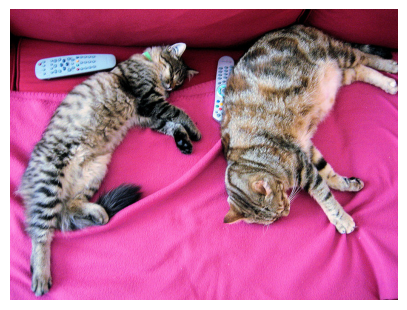

Q: Describe this image in one sentence.
A: In this image we can see two cats on the pink color cloth. There are two remote control on the right side of the image.

Q: How many cats are there?
A: There are two cats in the image.

Q: What objects are next to the cats?
A: There are two remote control remotes in the image.



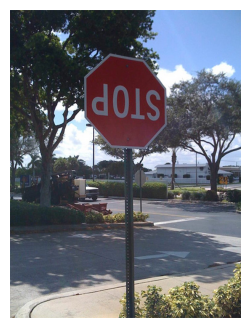

Q: What does the sign say?
A: The sign has the word "STOP" written on it.

Q: Is there anything unusual about the sign?
A: Yes, there is a vehicle on the sign.



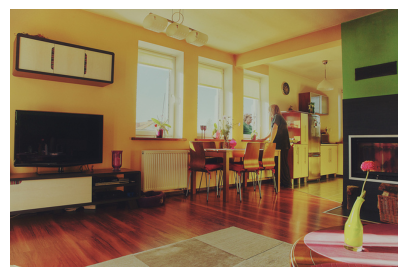

Q: List the objects you can see.
A: The image shows a living room with a dining area. The room has a warm and inviting atmosphere, with a high ceiling and large windows that let in plenty of natural light. The walls are painted in a warm yellow color, which gives the room a cozy and inviting feel.

In the foreground, there is a dining table with six chairs, arranged in a square. The chairs are uphol

Q: Is it day or night outside?
A: The image does not provide information about the time of day, so it cannot be determined if it is day or night.



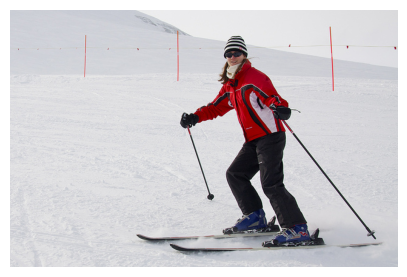

Q: What is the person doing?
A: The person is standing on a ski board.

Q: What is the weather like?
A: The snow is white in color, indicating a cold and clear weather.



In [ ]:
def ask(image, question, max_new_tokens=80):               # ask SmolVLM a question about an image
    messages = [{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": question}]}]   # the chat
    prompt = vlm_processor.apply_chat_template(messages, add_generation_prompt=True)   # chat -> text
    inputs = vlm_processor(text=prompt, images=[image], return_tensors="pt").to(device)   # preprocess and move to device
    with torch.no_grad():                                  # no gradients needed
        output_ids = vlm.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)   # generate (greedy)
    prompt_length = inputs["input_ids"].shape[1]           # number of prompt tokens
    new_ids = output_ids[:, prompt_length:]                # keep only the newly generated tokens
    answer = vlm_processor.batch_decode(new_ids, skip_special_tokens=True)[0]   # ids -> text
    return answer.strip()                                  # remove extra spaces


def show_and_ask(image, questions, max_new_tokens=80):     # show an image, then print questions and answers
    plt.figure(figsize=(5, 4))                             # figure
    plt.imshow(image)                                      # the image
    plt.axis("off")                                        # no axis
    plt.show()                                             # display
    for question in questions:                             # for every question
        print("Q:", question)                              # print the question
        print("A:", ask(image, question, max_new_tokens))  # print the model's answer
        print()                                            # empty line


show_and_ask(images["cats"], ["Describe this image in one sentence.", "How many cats are there?", "What objects are next to the cats?"])   # cats
show_and_ask(images["stop sign"], ["What does the sign say?", "Is there anything unusual about the sign?"])   # the sign is mounted upside-down!
show_and_ask(images["living room"], ["List the objects you can see.", "Is it day or night outside?"])         # living room
show_and_ask(images["skier"], ["What is the person doing?", "What is the weather like?"])                     # skier

> **Look closely at the stop sign:** it really is mounted **upside-down**. Small VLMs often answer from what they "expect" (stop signs say STOP and are red) and miss the unusual detail, or make one up.

### Probing for hallucinations
Researchers measure hallucination with yes/no questions about objects that **are** and **are not** in the image (the **POPE** benchmark). Questions that **assume** a non-existent object are especially tricky.

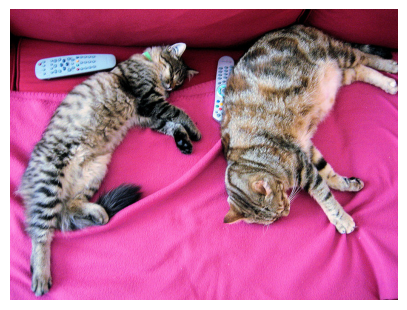

Q: Is there a cat in the image? Answer yes or no.
A: Yes.

Q: Is there a dog in the image? Answer yes or no.
A: No.

Q: What color is the dog in the image?
A: There is no dog present in the image.



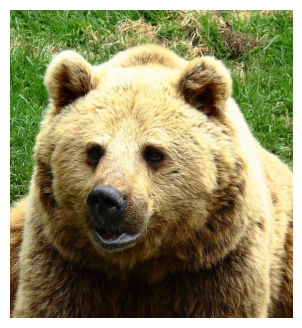

Q: Is there a person in the image? Answer yes or no.
A: Yes.

Q: What is the man next to the bear holding?
A: There is no man present in the image, and no other objects are visible.



In [ ]:
show_and_ask(images["cats"], ["Is there a cat in the image? Answer yes or no.",   # true object
                              "Is there a dog in the image? Answer yes or no.",   # absent object
                              "What color is the dog in the image?"], 40)         # assumes a dog that is not there
show_and_ask(images["bear"], ["Is there a person in the image? Answer yes or no.",   # absent object
                              "What is the man next to the bear holding?"], 40)      # assumes a man that is not there

### Does the model even need the image?
Ask about a **plain gray image**. If the model still describes things, it is answering from its language habits, not from vision.

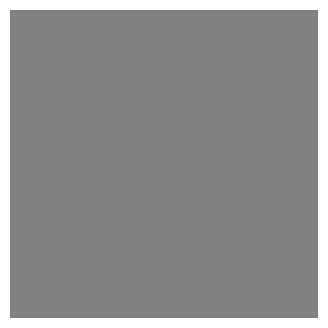

Q: Describe this image in one sentence.
A: In this image there is a black background.

Q: How many cats are there?
A: There are 2 cats.



In [ ]:
gray = Image.new("RGB", (512, 512), (128, 128, 128))       # a plain gray image
show_and_ask(gray, ["Describe this image in one sentence.", "How many cats are there?"])   # what does it say?

### Try it yourself
Change the address and the question. Any public image address works.

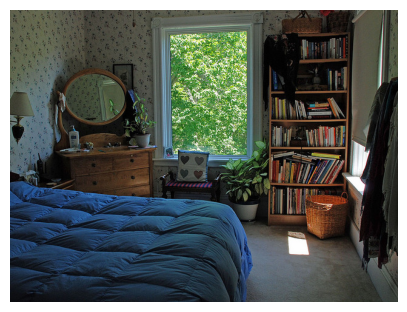

Q: What room is this, and what is the biggest piece of furniture?
A: This is a bedroom. The biggest piece of furniture is a bed.



In [ ]:
my_url = "http://images.cocodataset.org/val2017/000000000632.jpg"   # change this to any image address
my_question = "What room is this, and what is the biggest piece of furniture?"   # change this to any question
show_and_ask(load_image(my_url), [my_question])            # download, show, ask

---
# Part 8: Wrap-up (2:55 – 3:00)

## What we built
| What we wrote from scratch | Real-world counterpart |
|---|---|
| `patchify` + `nn.Linear` | `Conv2d(stride = patch size)` in every ViT |
| `attention`, `MultiHeadAttention` | fast attention kernels (FlashAttention) |
| `TransformerBlock`, `ViT` (86M, same as ViT-B/16) | CLIP / SigLIP image encoders |
| `TextEncoder`, `MiniCLIP`, `clip_loss` | CLIP, SigLIP |
| `TinyGPT`, `MiniLLaVA` | LLaVA, Qwen-VL, SmolVLM |
| `GatedCrossAttention`, `QueryResampler` | Flamingo, BLIP-2 |

## Five ideas to remember
1. **An image becomes a sequence of patch tokens**. After that, it is "just a transformer".
2. **Contrastive learning (CLIP)** puts images and text in one space, giving zero-shot classification and search for free.
3. **Generative VLM = vision encoder + projector + language model**, trained with next-word prediction on the answer.
4. **The number of visual tokens** is the main efficiency trade-off.
5. **Hallucination**: the language model's habits can override what is in the image. Always test with probes.

## Open research problems
* Counting, spatial reasoning, reading dense text (OCR)
* High-resolution images and **video** (too many tokens)
* Measuring and reducing hallucination; models that say "I don't know"
* Fair evaluation (benchmarks leaking into training data)

## Exercises
1. **Compositional generalization:** remove all *purple triangles* from Mini-CLIP's training data. Can it still recognize "a large purple triangle on the left"?
2. **Swap the connector:** replace the MLP projector in `MiniLLaVA` with `QueryResampler(dim=128, num_queries=8, heads=4)`. What happens to accuracy and speed?
3. **Unfreeze the vision encoder** in `MiniLLaVA` (`requires_grad = True`). Does accuracy improve?
4. **Two shapes per image:** extend Shapes World with relations ("a red circle left of a blue square"). Which model breaks first?
5. **Sampling:** change `generate` so it samples the next word from `softmax(scores / temperature)` instead of taking the maximum.
6. **Hallucination study:** write 20 yes/no questions about the COCO photos and measure SmolVLM's accuracy for present vs. absent objects.

## References
* Vaswani et al., *Attention Is All You Need*, 2017
* Dosovitskiy et al., *An Image is Worth 16x16 Words (ViT)*, 2020
* Radford et al., *CLIP*, 2021
* Li et al., *BLIP*, 2022; *BLIP-2*, 2023
* Alayrac et al., *Flamingo*, 2022
* Liu et al., *Visual Instruction Tuning (LLaVA)*, 2023
* Abnar & Zuidema, *Attention Rollout*, 2020
* Li et al., *POPE: Evaluating Object Hallucination*, 2023
* Marafioti et al., *SmolVLM*, 2025